# Fake Job Posting Detector (EMSCAD)

**Data:** 17,880 job postings, about 5% fraudulent.
**Split:** stratified 80/20 before any preprocessing; encoders and the fraud-profile feature are built from train data only, and the test set is used once for final evaluation.
**Models:** XGBoost baseline vs Naive Bayes and RIPPER; then SMOTE, Optuna tuning and isotonic calibration.

**Result (held-out test set, n = [3,576]):**

| Model | ROC-AUC | Precision (fraud) | Recall (fraud) |
|---|---|---|---|
| XGBoost baseline (threshold 0.5) | [0.990] | [0.576] | [0.942]] |
| XGBoost (validation-selected threshold) | [0.990] | [0.698] | [0.908] |
| Tuned + calibrated | [0.988] | [0.982] | [0.624] |

**Finding:** [one sentence on what SMOTE, tuning and calibration changed compared with the baseline]
**Limitations:** single dataset, about [173] fraud cases in the test set, no external validation.

In [1]:
import os, re
import numpy as np
import pandas as pd
from bs4 import BeautifulSoup

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from wordcloud import WordCloud

from sklearn.naive_bayes import MultinomialNB
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder,MinMaxScaler
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, precision_recall_curve,
                             average_precision_score,precision_score, recall_score, f1_score)
import numpy as np
import pandas as pd
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.calibration import CalibratedClassifierCV
import subprocess, sys
subprocess.run([sys.executable, '-m', 'pip', 'install', 'wittgenstein', '-q'], check=False)

import wittgenstein as lw

import xgboost as xgb

# Download required NLTK data
for resource in ['stopwords', 'wordnet', 'omw-1.4']:
    nltk.download(resource, quiet=True)

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

# Consistent colour palette
REAL_COLOR = '#2196F3'   # blue  → real postings
FAKE_COLOR = '#F44336'   # red   → fake postings
PALETTE    = [REAL_COLOR, FAKE_COLOR]

# List available input files
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.3/78.3 kB 1.3 MB/s eta 0:00:00
/kaggle/input/datasets/shivamb/real-or-fake-fake-jobposting-prediction/fake_job_postings.csv


## Step 1 — Load & Split
Split the raw data **before** any preprocessing to prevent data leakage.  
Stratified split preserves the ~5% fraud ratio in both train and test sets.

In [2]:
df = pd.read_csv('/kaggle/input/datasets/shivamb/real-or-fake-fake-jobposting-prediction/fake_job_postings.csv')

df_train, df_test = train_test_split(
    df,
    test_size    = 0.20,
    stratify     = df['fraudulent'],  # preserve ~5% fraud ratio in both sets
    random_state = 42
)
df_train = df_train.reset_index(drop=True)
df_test  = df_test.reset_index(drop=True)

print(f"Train: {len(df_train):,} rows  |  fraud rate: {df_train['fraudulent'].mean()*100:.2f}%")
print(f"Test : {len(df_test):,} rows  |  fraud rate: {df_test['fraudulent'].mean()*100:.2f}%")

Train: 14,304 rows  |  fraud rate: 4.84%
Test : 3,576 rows  |  fraud rate: 4.84%


## Step 1.5 — Exploratory Data Analysis (EDA)
A full look at the raw dataset before any transformation. We inspect structure, missing values, class balance, text length distributions, top categories, correlations, and word clouds.

In [3]:
# ─────────────────────────────────────────────────────────────────────────────
# 1. Basic dataset overview
# ─────────────────────────────────────────────────────────────────────────────
print("=" * 60)
print("HEAD (first 5 rows)")
print("=" * 60)
display(df.head())

print("\n" + "=" * 60)
print("SHAPE:", df.shape)
print("=" * 60)

print("\n" + "=" * 60)
print("DESCRIPTIVE STATISTICS")
print("=" * 60)
display(df.describe(include='all'))

print("\n" + "=" * 60)
print("MISSING VALUES (count + %)")
print("=" * 60)
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(2)
display(pd.DataFrame({'Missing': missing, '% Missing': missing_pct})[missing > 0].sort_values('% Missing', ascending=False))

HEAD (first 5 rows)


,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0



SHAPE: (17880, 18)

DESCRIPTIVE STATISTICS


,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
count,17880.000000,17880,17534,6333,2868,14572,17879,15184,10668,17880.000000,17880.000000,17880.000000,14409,10830,9775,12977,11425,17880.000000
unique,NaN,11231,3105,1337,874,1709,14801,11967,6204,NaN,NaN,NaN,5,7,13,131,37,NaN
top,NaN,English Teacher Abroad,"GB, LND, London",Sales,0-0,We help teachers get safe &amp; secure jobs ab...,"Play with kids, get paid for it Love travel? J...",University degree required. TEFL / TESOL / CEL...,See job description,NaN,NaN,NaN,Full-time,Mid-Senior level,Bachelor's Degree,Information Technology and Services,Information Technology,NaN
freq,NaN,311,718,551,142,726,379,410,726,NaN,NaN,NaN,11620,3809,5145,1734,1749,NaN
mean,8940.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.042897,0.795302,0.491723,NaN,NaN,NaN,NaN,NaN,0.048434
std,5161.655742,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.202631,0.403492,0.499945,NaN,NaN,NaN,NaN,NaN,0.214688
min,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,0.000000
25%,4470.750000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,1.000000,0.000000,NaN,NaN,NaN,NaN,NaN,0.000000
50%,8940.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,1.000000,0.000000,NaN,NaN,NaN,NaN,NaN,0.000000
75%,13410.250000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,1.000000,1.000000,NaN,NaN,NaN,NaN,NaN,0.000000



MISSING VALUES (count + %)


,Missing,% Missing
salary_range,15012,83.96
department,11547,64.58
required_education,8105,45.33
benefits,7212,40.34
required_experience,7050,39.43
function,6455,36.10
industry,4903,27.42
employment_type,3471,19.41
company_profile,3308,18.50
requirements,2696,15.08


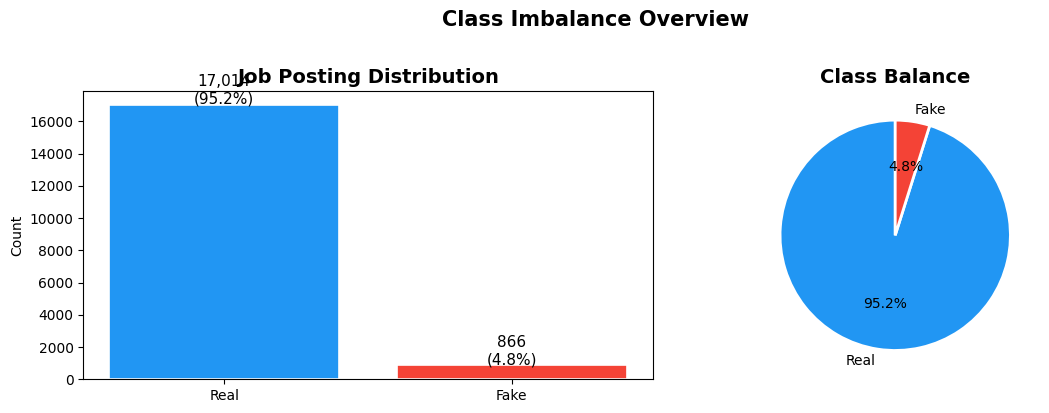

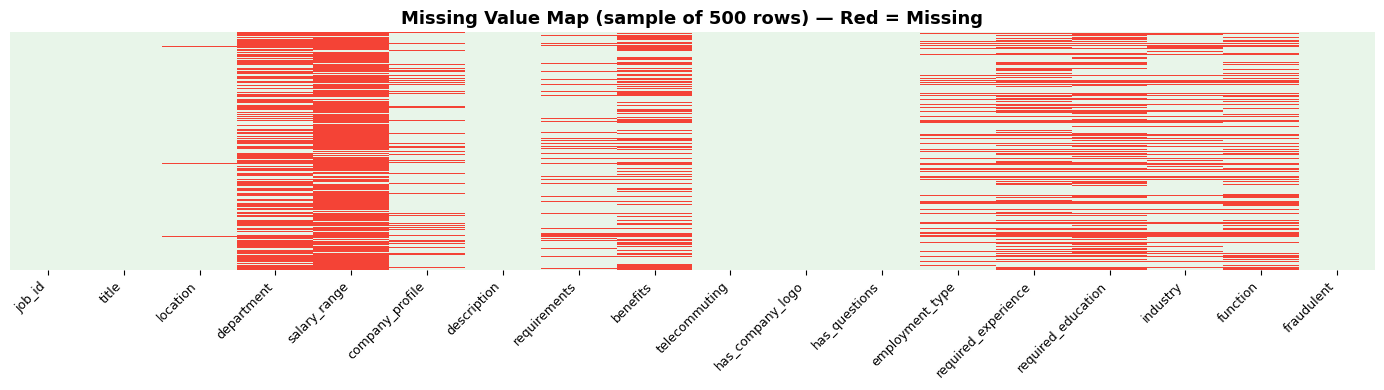

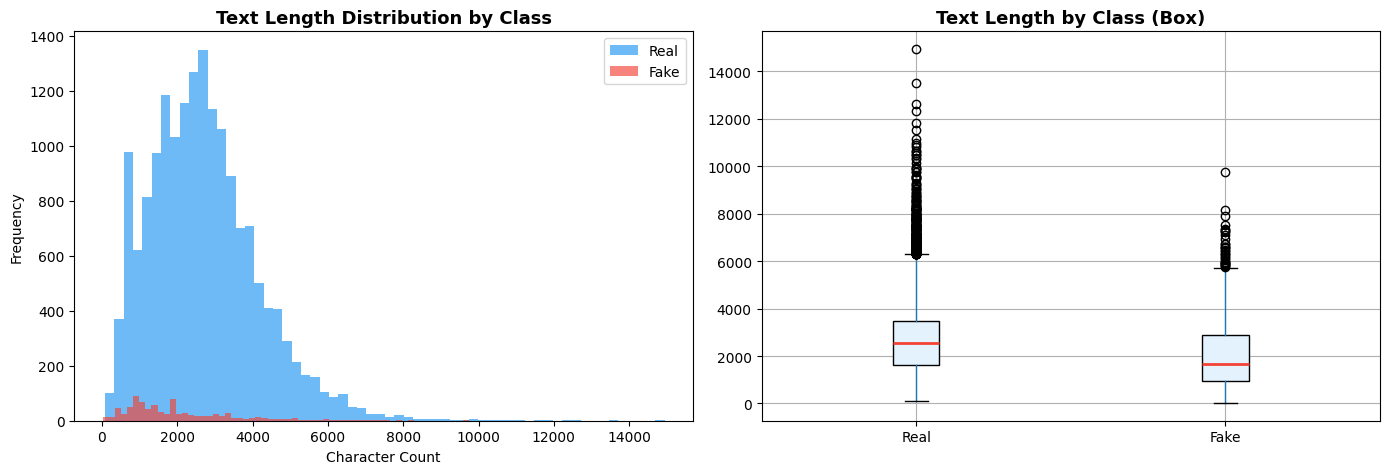

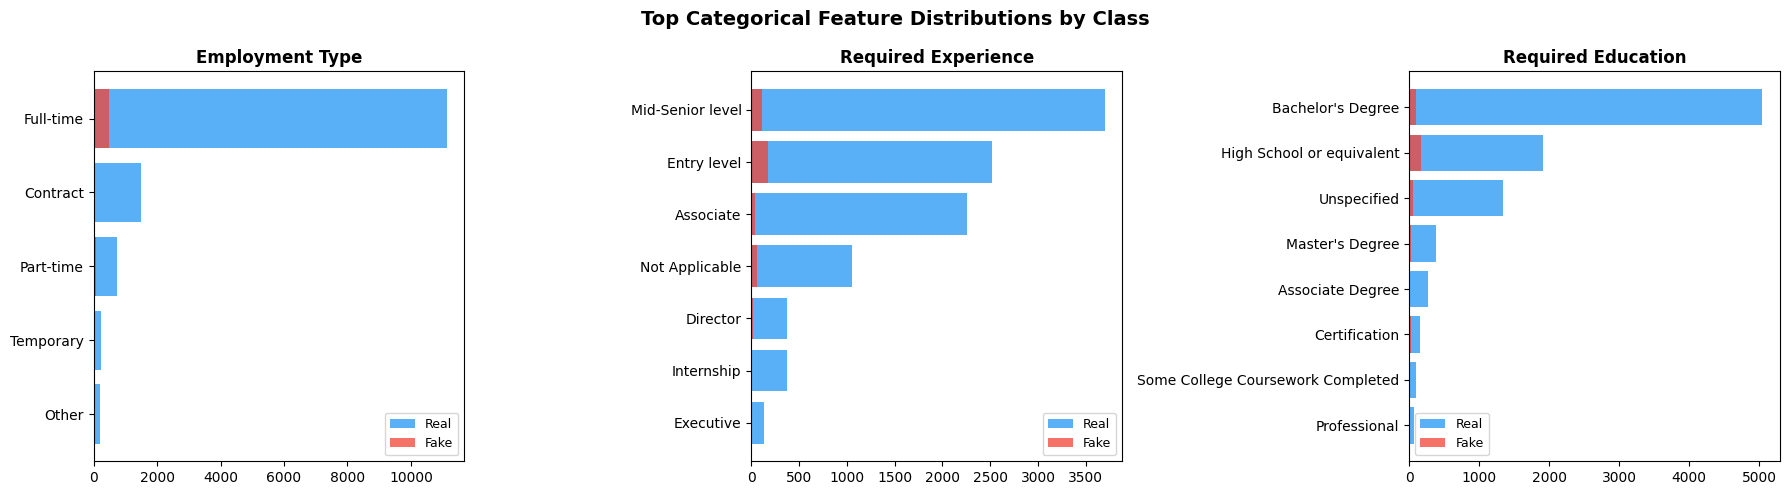

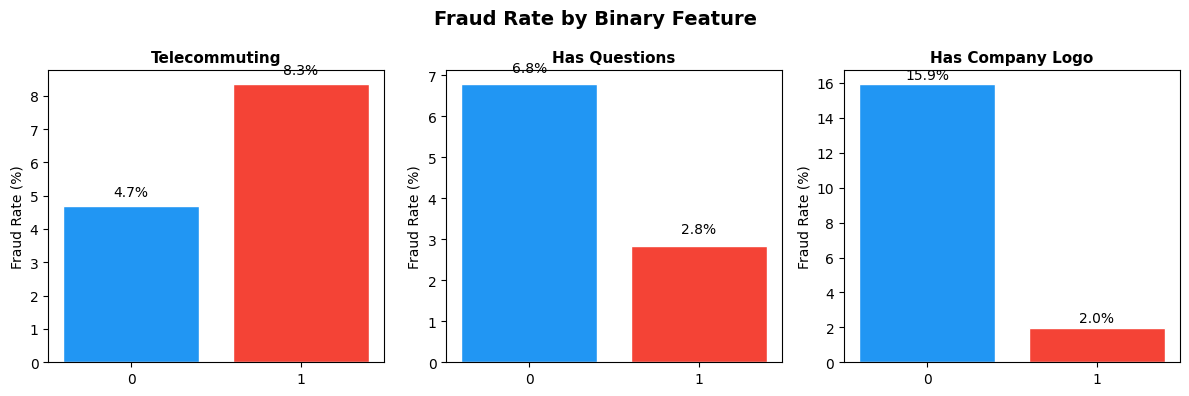

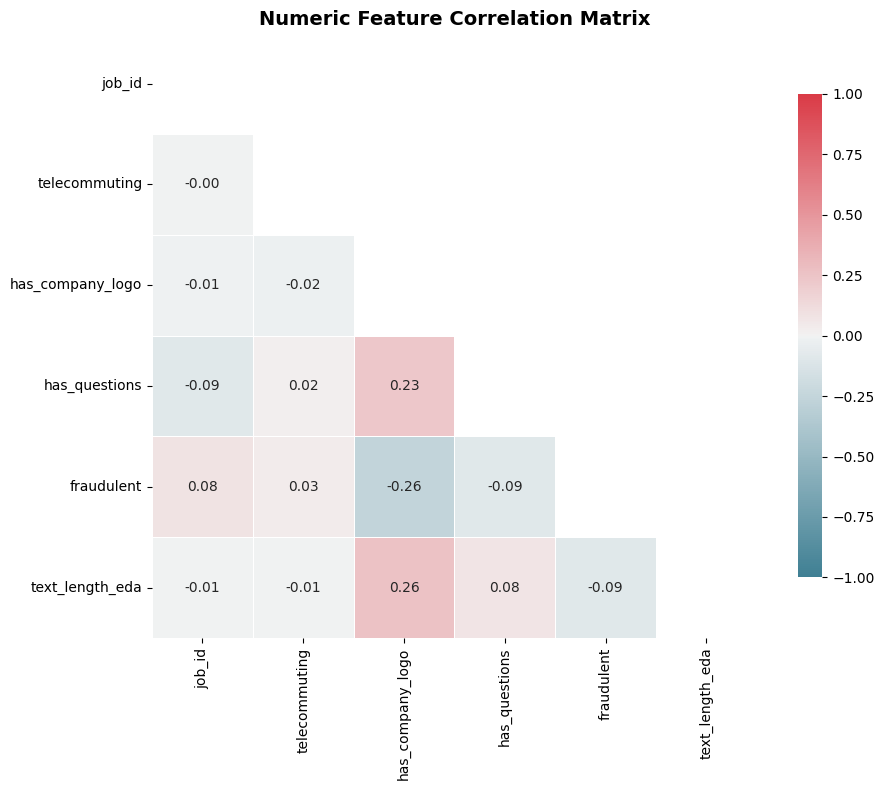

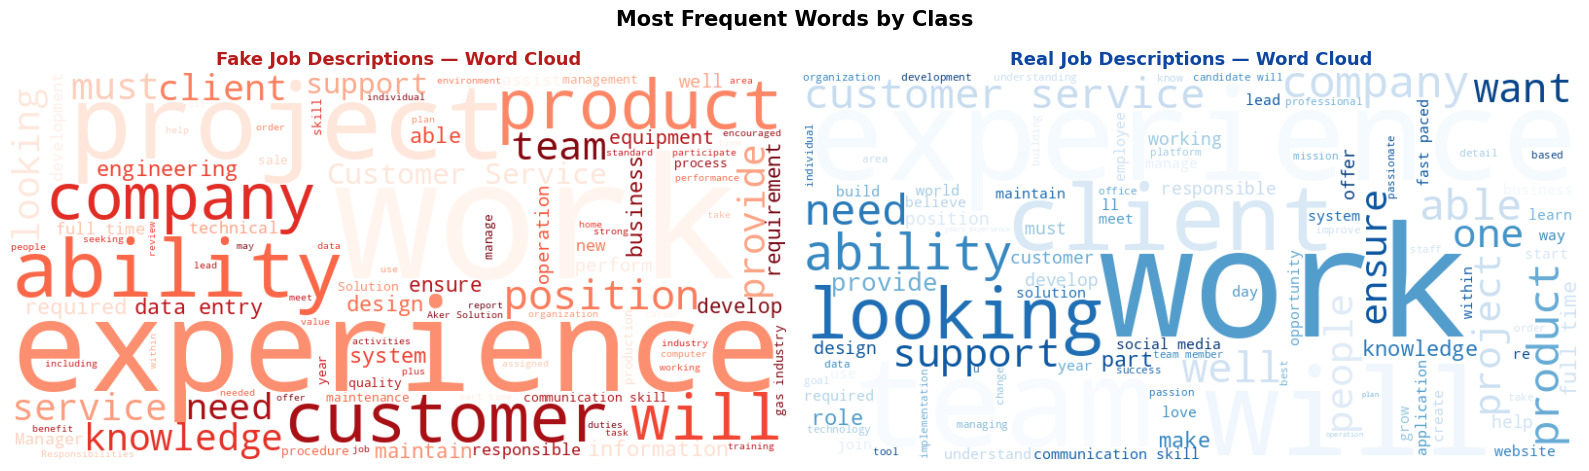

In [4]:
# ─────────────────────────────────────────────────────────────────────────────
# 2. Class Distribution — bar chart
# ─────────────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

counts = df['fraudulent'].value_counts()
axes[0].bar(['Real', 'Fake'], counts.values, color=PALETTE, edgecolor='white', linewidth=1.2)
axes[0].set_title('Job Posting Distribution', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Count')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 80, f'{v:,}\n({v/len(df)*100:.1f}%)', ha='center', fontsize=11)

axes[1].pie(counts.values, labels=['Real', 'Fake'], colors=PALETTE,
            autopct='%1.1f%%', startangle=90, wedgeprops=dict(edgecolor='white', linewidth=2))
axes[1].set_title('Class Balance', fontsize=14, fontweight='bold')

plt.suptitle('Class Imbalance Overview', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# ─────────────────────────────────────────────────────────────────────────────
# 3. Missing value heatmap
# ─────────────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 4))
missing_matrix = df.isnull().astype(int)
# Sample for visibility
sns.heatmap(missing_matrix.sample(min(500, len(df)), random_state=42),
            cbar=False, yticklabels=False, ax=ax,
            cmap=['#E8F5E9', '#F44336'])
ax.set_title('Missing Value Map (sample of 500 rows) — Red = Missing', fontsize=13, fontweight='bold')
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=9)
plt.tight_layout()
plt.show()

# ─────────────────────────────────────────────────────────────────────────────
# 4. Text length distribution by class
# ─────────────────────────────────────────────────────────────────────────────
df['text_length_eda'] = (
    df[['title', 'company_profile', 'description', 'requirements', 'benefits']]
    .fillna('').astype(str).agg(' '.join, axis=1).str.len()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for label, color, name in [(0, REAL_COLOR, 'Real'), (1, FAKE_COLOR, 'Fake')]:
    subset = df[df['fraudulent'] == label]['text_length_eda']
    axes[0].hist(subset, bins=60, alpha=0.65, color=color, label=name, edgecolor='none')
axes[0].set_title('Text Length Distribution by Class', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Character Count')
axes[0].set_ylabel('Frequency')
axes[0].legend()

df.boxplot(column='text_length_eda', by='fraudulent', ax=axes[1],
           patch_artist=True,
           boxprops=dict(facecolor='#E3F2FD'),
           medianprops=dict(color='#F44336', linewidth=2))
axes[1].set_title('Text Length by Class (Box)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('')
axes[1].set_xticklabels(['Real', 'Fake'])
plt.suptitle('')
plt.tight_layout()
plt.show()

# ─────────────────────────────────────────────────────────────────────────────
# 5. Top categorical feature distributions
# ─────────────────────────────────────────────────────────────────────────────
cat_cols = ['employment_type', 'required_experience', 'required_education']
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, cat_cols):
    order = df[col].value_counts().head(8).index
    for label, color, name in [(0, REAL_COLOR, 'Real'), (1, FAKE_COLOR, 'Fake')]:
        subset = df[df['fraudulent'] == label][col].value_counts().reindex(order, fill_value=0)
        ax.barh(order[::-1], subset.values[::-1], alpha=0.75, color=color, label=name)
    ax.set_title(col.replace('_', ' ').title(), fontsize=12, fontweight='bold')
    ax.legend(fontsize=9)
plt.suptitle('Top Categorical Feature Distributions by Class', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ─────────────────────────────────────────────────────────────────────────────
# 6. Binary flag fraud rates — how often each flag appears in fake vs real
# ─────────────────────────────────────────────────────────────────────────────
binary_flags = ['telecommuting', 'has_questions', 'has_company_logo']
fig, axes = plt.subplots(1, len(binary_flags), figsize=(12, 4))
for ax, col in zip(axes, binary_flags):
    if col not in df.columns:
        ax.axis('off')
        continue
    cross = df.groupby(col)['fraudulent'].mean() * 100
    bars = ax.bar(cross.index.astype(str), cross.values,
                  color=[REAL_COLOR, FAKE_COLOR][:len(cross)], edgecolor='white')
    ax.set_title(col.replace('_', ' ').title(), fontsize=11, fontweight='bold')
    ax.set_ylabel('Fraud Rate (%)')
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                f'{bar.get_height():.1f}%', ha='center', fontsize=10)
plt.suptitle('Fraud Rate by Binary Feature', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ─────────────────────────────────────────────────────────────────────────────
# 7. Numeric correlation heatmap (on numeric columns of raw df)
# ─────────────────────────────────────────────────────────────────────────────
numeric_df = df.select_dtypes(include=[np.number])
corr = numeric_df.corr()

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.zeros_like(corr, dtype=bool)
mask[np.triu_indices_from(mask)] = True   # show lower triangle only
sns.heatmap(corr, mask=mask,
            cmap=sns.diverging_palette(220, 10, as_cmap=True),
            vmin=-1, vmax=1, center=0,
            square=True, linewidths=0.5, annot=True, fmt='.2f',
            ax=ax, cbar_kws={'shrink': 0.8})
ax.set_title('Numeric Feature Correlation Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ─────────────────────────────────────────────────────────────────────────────
# 8. Word Clouds — Fake vs Real
# ─────────────────────────────────────────────────────────────────────────────
text_cols = ['title', 'company_profile', 'description', 'requirements', 'benefits']

def combine_text(subset_df):
    return ' '.join(
        subset_df[text_cols].fillna('').astype(str).agg(' '.join, axis=1).tolist()
    )

fake_text = combine_text(df[df['fraudulent'] == 1])
real_text = combine_text(df[df['fraudulent'] == 0])

wc_fake = WordCloud(width=800, height=400, background_color='white',
                    colormap='Reds', max_words=100).generate(fake_text)
wc_real = WordCloud(width=800, height=400, background_color='white',
                    colormap='Blues', max_words=100).generate(real_text)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].imshow(wc_fake, interpolation='bilinear')
axes[0].set_title('Fake Job Descriptions — Word Cloud', fontsize=13, fontweight='bold', color='#B71C1C')
axes[0].axis('off')

axes[1].imshow(wc_real, interpolation='bilinear')
axes[1].set_title('Real Job Descriptions — Word Cloud', fontsize=13, fontweight='bold', color='#0D47A1')
axes[1].axis('off')

plt.suptitle('Most Frequent Words by Class', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

## Step 2 — Text Cleaning Helpers
Two cleaning pipelines:
- **`clean_text_for_ml`** — heavy preprocessing (lemmatize, remove stopwords) for XGBoost/SVM/RF
- **`clean_text_for_dl`** — light preprocessing (preserve punctuation) for DistilBERT/BiLSTM

In [5]:
def clean_text_for_ml(text):
    """
    Heavy preprocessing for traditional ML (XGBoost, SVM, RF with TF-IDF).
    Strips HTML, lowercases, removes noise, lemmatizes, removes stopwords.
    Uses str.split() instead of word_tokenize — ~10x faster, same quality.
    """
    try:
        if not isinstance(text, str) or not text.strip():
            return ''
        text = BeautifulSoup(text, "html.parser").get_text()     # strip HTML
        text = re.sub(r'([.!?])([A-Z])', r'\1 \2', text)       # fix run-on sentences
        text = re.sub(r'([a-z0-9])([A-Z])', r'\1 \2', text)    # fix camelCase
        text = text.lower()
        text = re.sub(r'https?://\S+|www\.\S+', '', text)      # remove URLs
        text = re.sub(r'\S+@\S+', '', text)                     # remove emails
        text = re.sub(r'[^a-z\s]', ' ', text)                   # keep letters only
        text = re.sub(r'\s+', ' ', text).strip()
        if not text:
            return ''
        tokens = [
            lemmatizer.lemmatize(w)
            for w in text.split()
            if w not in stop_words and len(w) > 2
        ]
        return ' '.join(tokens)
    except Exception as e:
        print(f"clean_text_for_ml error: {e}")
        return ''


def clean_text_for_dl(text):
    """
    Light preprocessing for Deep Learning (DistilBERT, BiLSTM).
    Preserves punctuation and sentence structure that transformers rely on.
    """
    try:
        if not isinstance(text, str) or not text.strip():
            return ''
        text = BeautifulSoup(text, "html.parser").get_text()
        text = re.sub(r'([.!?])([A-Z])', r'\1 \2', text)
        text = re.sub(r'([a-z0-9])([A-Z])', r'\1 \2', text)
        text = text.lower()
        text = re.sub(r'\S+@\S+', '[EMAIL]', text)              # mask emails (keep signal)
        text = re.sub(r'[^a-z0-9\s.,!?\-]', ' ', text)         # allow punctuation
        return re.sub(r'\s+', ' ', text).strip()
    except Exception as e:
        print(f"clean_text_for_dl error: {e}")
        return ''

print("Text cleaning functions defined.")

Text cleaning functions defined.


## Step 3 — Structured Feature Helpers
Parse location strings (`'US, NY, New York'` → city/state/country)  
and salary ranges (`'$50,000-$80,000'` → min/max/currency).

In [6]:
def extract_location(location):
    """Parse 'US, NY, New York' → (city, state, country). Returns 'unknown' for missing."""
    if pd.isna(location) or location == '':
        return 'unknown', 'unknown', 'unknown'
    parts = [p.strip().lower() for p in str(location).split(',')]
    if len(parts) >= 3: return parts[2], parts[1], parts[0]
    if len(parts) == 2: return parts[1], parts[0], 'unknown'
    return parts[0], 'unknown', 'unknown'


def extract_salary(salary_range):
    """Parse '$50,000-$80,000' → (min, max, currency). Returns (0.0, 0.0, 'unknown') if missing."""
    if pd.isna(salary_range) or salary_range == '':
        return 0.0, 0.0, 'unknown'
    nums = re.findall(r'\d+(?:,\d{3})*(?:\.\d+)?', str(salary_range))
    if len(nums) >= 2:
        return float(nums[0].replace(',','')), float(nums[1].replace(',','')), 'usd'
    if len(nums) == 1:
        v = float(nums[0].replace(',',''))
        return v, v, 'usd'
    return 0.0, 0.0, 'unknown'

print("Structured feature helpers defined.")

Structured feature helpers defined.


## Step 4 — Main Preprocessing Pipeline
Applied independently to train and test — **no fitting occurs here**, only deterministic transformations.  
This keeps the pipeline leak-free.

In [7]:
def preprocess_dataset(input_df):
    """
    Applies structural and text preprocessing to a raw split (train or test).
    No fitting occurs — all steps are deterministic transformations.
    """
    print(f"Preprocessing {len(input_df):,} rows...")
    df = input_df.copy()

    # Drop ID column — not a feature
    df.drop(columns=['job_id'], errors='ignore', inplace=True)

    # Fill missing text fields with empty string
    for col in ['title','location','department','salary_range',
                'company_profile','description','requirements','benefits']:
        df[col] = df.get(col, pd.Series()).fillna('')

    # Fill missing categorical fields with 'Unknown'
    for col in ['employment_type','required_experience','required_education','industry','function']:
        df[col] = df.get(col, pd.Series()).fillna('Unknown')

    # Extract structured location features
    loc = df['location'].apply(lambda x: pd.Series(extract_location(x)))
    loc.columns = ['city', 'state', 'country']
    df = pd.concat([df, loc], axis=1)

    # Extract structured salary features
    sal = df['salary_range'].apply(lambda x: pd.Series(extract_salary(x)))
    sal.columns = ['salary_min', 'salary_max', 'currency']
    df = pd.concat([df, sal], axis=1)

    # Presence flags (1 = field exists, 0 = missing/empty)
    for col, flag in [('salary_range','has_salary'), ('department','has_department'),
                      ('company_profile','has_company_profile'),
                      ('requirements','has_requirements'), ('benefits','has_benefits')]:
        df[flag] = (df[col].str.strip() != '').astype(int)

    # Combine key text fields into one document per posting
    df['text'] = df[['title','company_profile','description','requirements','benefits']]\
                   .apply(lambda r: '. '.join(r.astype(str)), axis=1).str.strip()

    # Apply both cleaning pipelines
    print("  Cleaning text for ML...")
    df['clean_text']    = df['text'].apply(clean_text_for_ml)
    print("  Cleaning text for DL...")
    df['clean_text_dl'] = df['text'].apply(clean_text_for_dl)

    # Text length features
    df['text_length']       = df['text'].str.len()
    df['clean_text_length'] = df['clean_text'].str.len()
    df['word_count']        = df['clean_text'].str.split().str.len()

    # Drop rows where cleaning produced empty text (safety net)
    before = len(df)
    df = df[df['clean_text'].str.len() > 0].copy()
    if len(df) < before:
        print(f"  Dropped {before - len(df)} empty-text rows")

    print(f"  Done. Shape: {df.shape}")
    return df


# Run preprocessing on each split independently
df_train_processed = preprocess_dataset(df_train)
df_test_processed  = preprocess_dataset(df_test)

assert len(df_train_processed) + len(df_test_processed) <= len(df), "Row count mismatch"
print(f"\nTrain processed: {df_train_processed.shape}")
print(f"Test  processed: {df_test_processed.shape}")

Preprocessing 14,304 rows...
  Cleaning text for ML...
  Cleaning text for DL...
  Done. Shape: (14304, 34)
Preprocessing 3,576 rows...
  Cleaning text for ML...
  Cleaning text for DL...
  Done. Shape: (3576, 34)

Train processed: (14304, 34)
Test  processed: (3576, 34)


## Step 5 — Binary Feature Engineering
30 binary fraud-signal features split into three groups:
- **Textual** (1–12): spam words, money mentions, email patterns, formatting
- **Structural** (13–25): presence/absence and length of key sections
- **Contextual** (26–30): company legitimacy signals

> `fraud_profiles` is built from **train labels only** — applying it to test is safe (no leakage).

In [8]:
# ── Keyword lists ────────────────────────────────────────────────────────────
SPAM_WORDS = [
    "easy job", "work from home", "make money", "earn money", "be your own boss",
    "no experience", "unlimited income", "financial freedom", "passive income",
    "guaranteed income", "quick cash", "get paid", "hiring immediately",
    "urgently hiring", "part time from home", "flexible hours unlimited"
]
MONEY_WORDS      = ["money","cash","salary","earn","income","pay","dollar","compensation"]
EXTERNAL_PROMPTS = [
    "follow the link","click here","visit our website","apply online at",
    "send resume","send cv","email us","contact us at","apply at",
    "register at","sign up at","fill out the form"
]
NON_ORG_DOMAINS = ["gmail","yahoo","hotmail","outlook","aol","mail.com","protonmail"]
LOW_EDUCATION   = ["high school","hs diploma","some high school","no degree","no education"]

def _s(col, row):
    """Safe string getter — returns '' for missing or non-string values."""
    v = row.get(col, "")
    return v if isinstance(v, str) else ""

def _short(col, df_feat):
    """Returns 1 if field has fewer than 60 words (suspiciously brief)."""
    return df_feat[col].apply(lambda x: int(len(str(x).split()) < 60) if isinstance(x, str) else 1)

def _has_html_list(text):
    """Returns 1 if text contains HTML list tags (<ul>, <ol>, <li>)."""
    return int(bool(re.search(r"<(ul|ol|li)\b", str(text), re.IGNORECASE)))


def add_binary_features(df, fraud_profiles):
    f = df.copy()

    f["containsSpamWord"] = f.apply(
        lambda r: int(any(w in (_s("title",r)+" "+_s("description",r)).lower() for w in SPAM_WORDS)), axis=1)
    f["hasConsecutivePunctuation"] = f.apply(
        lambda r: int(bool(re.search(r"!{2,}", _s("title",r)+" "+_s("description",r)))), axis=1)
    f["hasMoneyInTitle"]       = f.apply(lambda r: int(any(w in _s("title",r).lower()       for w in MONEY_WORDS)), axis=1)
    f["hasMoneyInDescription"] = f.apply(lambda r: int(any(w in _s("description",r).lower() for w in MONEY_WORDS)), axis=1)
    f["hasExternalPrompt"] = f.apply(
        lambda r: int(any(p in (_s("description",r)+" "+_s("requirements",r)).lower() for p in EXTERNAL_PROMPTS)), axis=1)

    def _non_org_email(r):
        text   = _s("description",r) + " " + _s("requirements",r)
        emails = re.findall(r"[\w.\-]+@[\w.\-]+", text)
        return int(any(any(d in e.lower() for d in NON_ORG_DOMAINS) for e in emails))
    f["hasNonOrgEmailLinks"] = f.apply(_non_org_email, axis=1)

    f["isTelecommuting"] = f["telecommuting"].fillna(0).astype(int)
    f["hasConsecutiveCapitalLetters"] = f.apply(
        lambda r: int(bool(re.search(r"[A-Z]{10,}", _s("title",r)+" "+_s("description",r)))), axis=1)
    f["educationLevelLow"] = f.apply(
        lambda r: int(any(l in _s("required_education",r).lower() for l in LOW_EDUCATION)), axis=1)
    f["hasBoldTextInDescription"] = f.apply(
        lambda r: int(bool(re.search(r"<(b|strong)\b", _s("description",r), re.IGNORECASE))), axis=1)
    f["hasBoldTextInBenefits"] = f.apply(
        lambda r: int(bool(re.search(r"<(b|strong)\b", _s("benefits",r), re.IGNORECASE))), axis=1)
    f["basedInUS"] = f.apply(
        lambda r: int("us" in _s("location",r).lower() or "united states" in _s("location",r).lower()), axis=1)

    f["hasCompanyProfile"] = f["company_profile"].apply(lambda x: int(isinstance(x, str) and len(x.strip()) > 0))
    f["hasCompanyLogo"]    = f["has_company_logo"].fillna(0).astype(int)
    f["hasJobIndustry"]       = f["industry"].apply(    lambda x: int(isinstance(x, str) and len(x.strip()) > 0))
    f["hasScreeningQuestion"] = f["has_questions"].fillna(0).astype(int)
    f["hasJobDescription"]    = f["description"].apply( lambda x: int(isinstance(x, str) and len(x.strip()) > 0))
    f["hasSkillRequirement"]  = f["requirements"].apply(lambda x: int(isinstance(x, str) and len(x.strip()) > 0))
    f["hasBenefits"]          = f["benefits"].apply(    lambda x: int(isinstance(x, str) and len(x.strip()) > 0))

    f["hasShortDescription"]    = _short("description",     f)
    f["hasShortCompanyProfile"] = _short("company_profile", f)
    f["hasShortRequirements"]   = _short("requirements",    f)
    f["hasShortBenefits"]       = _short("benefits",        f)

    f["hasHTMLListInRequirements"] = f["requirements"].apply(_has_html_list)
    f["hasHTMLListInBenefits"]     = f["benefits"].apply(_has_html_list)

    f["hasCompanyName"] = f.apply(
        lambda r: int(bool(re.match(r"^([A-Z][a-zA-Z&.,]+ ){1,5}", _s("company_profile",r)))), axis=1)

    f["hasCompanyWebsite"] = 0
    f["hasMaturedWebsite"] = 0
    f["hasLinkedInPage"]   = 0

    f["previouslySeenAsFraudulent"] = f["company_profile"].apply(
        lambda x: int(str(x).strip() in fraud_profiles) if isinstance(x, str) else 0)

    return f


fraud_profiles = set(
    df_train_processed.loc[df_train_processed['fraudulent'] == 1, 'company_profile']
    .dropna().str.strip().loc[lambda x: x != ""]
)

df_train_processed = add_binary_features(df_train_processed, fraud_profiles)
df_test_processed  = add_binary_features(df_test_processed,  fraud_profiles)

# Leave-one-out for TRAIN rows: a row must not see its own label
prof     = df_train_processed['company_profile'].str.strip()
is_fraud = df_train_processed['fraudulent'].eq(1)
fraud_counts = prof[is_fraud & prof.ne('')].value_counts()
others = prof.map(fraud_counts).fillna(0) - is_fraud.astype(int)
df_train_processed['previouslySeenAsFraudulent'] = ((others > 0) & prof.ne('')).astype(int)

print(f"Train with binary features: {df_train_processed.shape}")
print(f"Test  with binary features: {df_test_processed.shape}")

df_train_processed.to_csv('/kaggle/working/train_processed.csv', index=False)
df_test_processed.to_csv( '/kaggle/working/test_processed.csv',  index=False)

Train with binary features: (14304, 64)
Test  with binary features: (3576, 64)


### EDA — Binary Feature Fraud Rates
After engineering the 30 binary flags, we visualise which ones are the most discriminative.

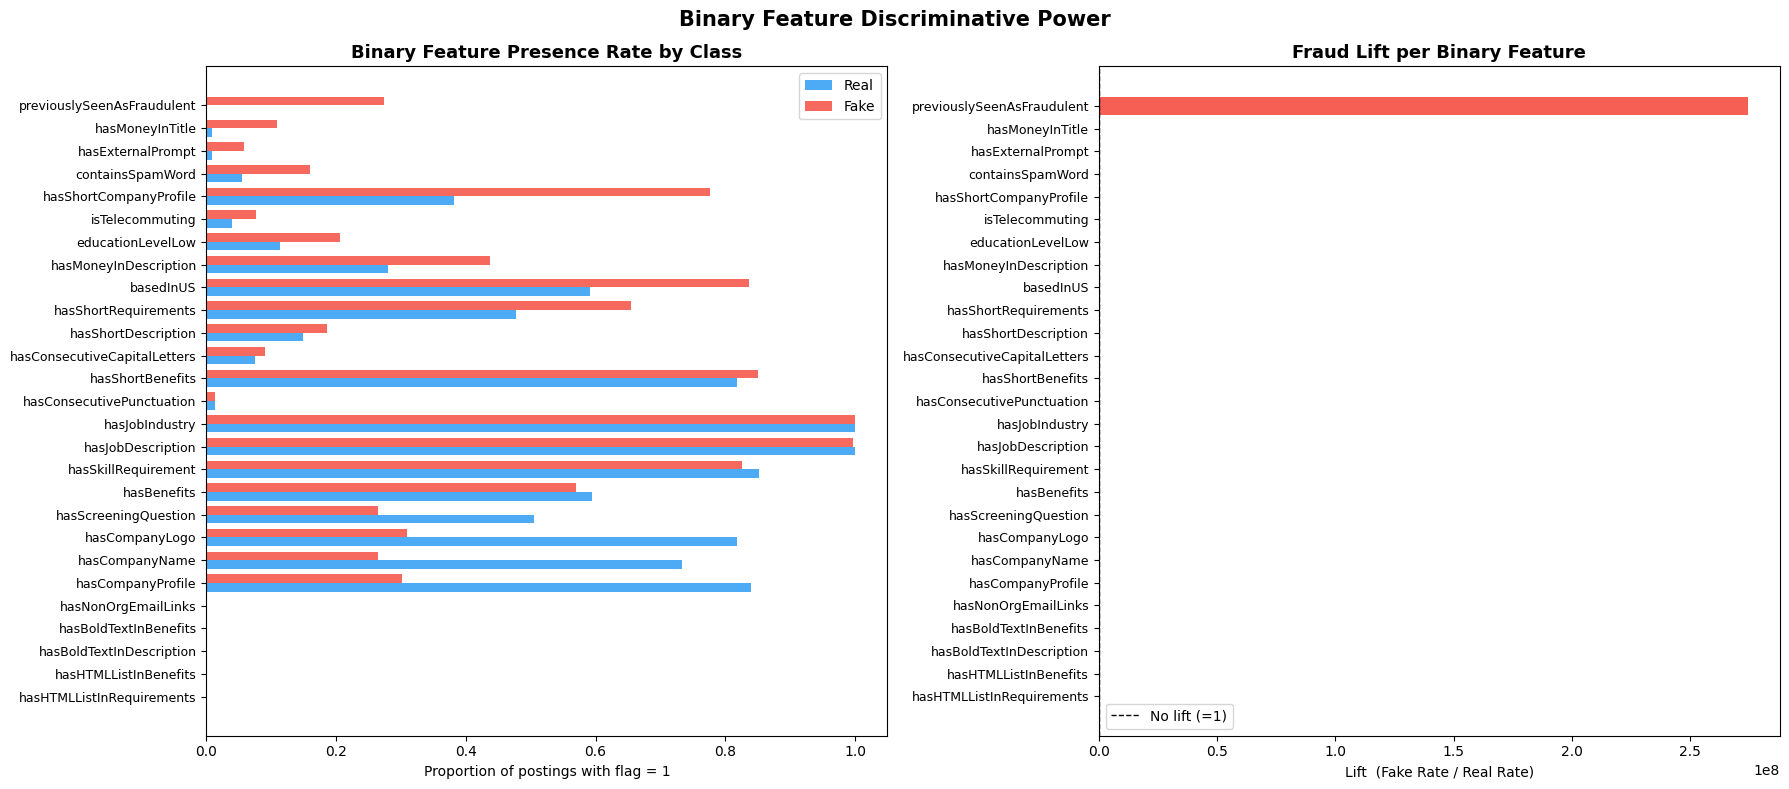

In [9]:
BINARY_FEATURES = [
    "containsSpamWord","hasConsecutivePunctuation","hasMoneyInTitle","hasMoneyInDescription",
    "hasExternalPrompt","hasNonOrgEmailLinks","isTelecommuting","hasConsecutiveCapitalLetters",
    "educationLevelLow","hasBoldTextInDescription","hasBoldTextInBenefits","basedInUS",
    "hasCompanyProfile","hasCompanyLogo","hasJobIndustry","hasScreeningQuestion",
    "hasJobDescription","hasSkillRequirement","hasBenefits","hasShortDescription",
    "hasShortCompanyProfile","hasShortRequirements","hasShortBenefits",
    "hasHTMLListInRequirements","hasHTMLListInBenefits","hasCompanyName","previouslySeenAsFraudulent"
]

fraud_rates = (
    df_train_processed[BINARY_FEATURES + ['fraudulent']]
    .groupby('fraudulent')[BINARY_FEATURES].mean().T
)
fraud_rates.columns = ['Real Rate', 'Fake Rate']
fraud_rates['Lift'] = fraud_rates['Fake Rate'] / (fraud_rates['Real Rate'] + 1e-9)
fraud_rates = fraud_rates.sort_values('Lift', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# Left: side-by-side bars
x = np.arange(len(fraud_rates))
w = 0.38
axes[0].barh(x + w/2, fraud_rates['Real Rate'], w, color=REAL_COLOR, alpha=0.8, label='Real')
axes[0].barh(x - w/2, fraud_rates['Fake Rate'], w, color=FAKE_COLOR, alpha=0.8, label='Fake')
axes[0].set_yticks(x)
axes[0].set_yticklabels(fraud_rates.index, fontsize=9)
axes[0].set_xlabel('Proportion of postings with flag = 1')
axes[0].set_title('Binary Feature Presence Rate by Class', fontsize=13, fontweight='bold')
axes[0].legend()
axes[0].invert_yaxis()

# Right: lift chart
colors = [FAKE_COLOR if v > 1.5 else ('#FF9800' if v > 1 else REAL_COLOR) for v in fraud_rates['Lift']]
axes[1].barh(x, fraud_rates['Lift'], color=colors, alpha=0.85)
axes[1].axvline(1, color='black', linestyle='--', linewidth=1, label='No lift (=1)')
axes[1].set_yticks(x)
axes[1].set_yticklabels(fraud_rates.index, fontsize=9)
axes[1].set_xlabel('Lift  (Fake Rate / Real Rate)')
axes[1].set_title('Fraud Lift per Binary Feature', fontsize=13, fontweight='bold')
axes[1].legend()
axes[1].invert_yaxis()

plt.suptitle('Binary Feature Discriminative Power', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

## Step 6 — Encoding
All encoders are **fit on train only**, then applied to test — this is the key rule preventing leakage.

| Feature type | Strategy | Reason |
|---|---|---|
| Numeric | StandardScaler | Zero mean, unit variance |
| Low-cardinality categorical | OneHotEncoder | Few unique values |
| High-cardinality categorical | LabelEncoder | Avoids column explosion |

In [10]:
feature_types = {
    'salary_min': 'NUMERIC', 'salary_max': 'NUMERIC',
    'text_length': 'NUMERIC', 'clean_text_length': 'NUMERIC', 'word_count': 'NUMERIC',
    'employment_type': 'OHE', 'required_experience': 'OHE',
    'required_education': 'OHE', 'currency': 'OHE',
    'city': 'LE', 'state': 'LE', 'country': 'LE', 'industry': 'LE', 'function': 'LE'
}

numeric_features = [f for f,t in feature_types.items() if t == 'NUMERIC']
ohe_features     = [f for f,t in feature_types.items() if t == 'OHE']
le_features      = [f for f,t in feature_types.items() if t == 'LE']

df_train_encoded = df_train_processed.copy()
df_test_encoded  = df_test_processed.copy()

scaler = StandardScaler()
df_train_encoded[numeric_features] = scaler.fit_transform(df_train_encoded[numeric_features])
df_test_encoded[numeric_features]  = scaler.transform(df_test_encoded[numeric_features])

ohe = OneHotEncoder(sparse_output=False, drop='first', handle_unknown='ignore')
ohe.fit(df_train_encoded[ohe_features])

ohe_cols  = ohe.get_feature_names_out(ohe_features)
train_ohe = pd.DataFrame(ohe.transform(df_train_encoded[ohe_features]), columns=ohe_cols, index=df_train_encoded.index)
test_ohe  = pd.DataFrame(ohe.transform(df_test_encoded[ohe_features]),  columns=ohe_cols, index=df_test_encoded.index)

df_train_encoded = pd.concat([df_train_encoded.drop(columns=ohe_features), train_ohe], axis=1)
df_test_encoded  = pd.concat([df_test_encoded.drop(columns=ohe_features),  test_ohe],  axis=1)

for col in le_features:
    le = LabelEncoder()
    le.fit(df_train_encoded[col].astype(str))
    df_train_encoded[col] = le.transform(df_train_encoded[col].astype(str))
    df_test_encoded[col]  = df_test_encoded[col].astype(str).apply(
        lambda x, le=le: le.transform([x])[0] if x in le.classes_ else -1
    )

print(f"Train encoded: {df_train_encoded.shape}")
print(f"Test  encoded: {df_test_encoded.shape}")

df_train_encoded.to_csv('/kaggle/working/train_encoded.csv', index=False)
df_test_encoded.to_csv( '/kaggle/working/test_encoded.csv',  index=False)

Train encoded: (14304, 86)
Test  encoded: (3576, 86)


## Step 7 — Model Training (XGBoost/NaiveBayes/Ripper)
Key design decisions:
- `scale_pos_weight` handles the ~95/5 class imbalance
- Early stopping uses a **validation set carved from train** (not the test set)
- Regularization params (`reg_alpha`, `reg_lambda`, `gamma`) prevent overfitting

In [11]:
DROP_COLS = [
    'title','location','department','salary_range','company_profile',
    'description','requirements','benefits','employment_type',
    'required_experience','required_education','industry','function',
    'text','clean_text','clean_text_dl','currency',
    'has_company_profile', 'has_company_logo',
]
TARGET = 'fraudulent'

X_train = df_train_encoded.drop(columns=[TARGET] + [c for c in DROP_COLS if c in df_train_encoded.columns])
y_train = df_train_encoded[TARGET]
X_test  = df_test_encoded.drop( columns=[TARGET] + [c for c in DROP_COLS if c in df_test_encoded.columns])
y_test  = df_test_encoded[TARGET]

obj_cols = X_train.select_dtypes(include='object').columns.tolist()
if obj_cols:
    print(f"Dropping non-numeric columns: {obj_cols}")
    X_train.drop(columns=obj_cols, inplace=True)
    X_test.drop( columns=obj_cols, inplace=True)

print(f"X_train: {X_train.shape}  |  X_test: {X_test.shape}")

scale_pos_weight = len(y_train[y_train==0]) / len(y_train[y_train==1])
print(f"scale_pos_weight: {scale_pos_weight:.2f}")

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.15, stratify=y_train, random_state=42
)
print(f"Train subset: {X_tr.shape}  |  Validation: {X_val.shape}")

model = xgb.XGBClassifier(
    n_estimators          = 1000,
    learning_rate         = 0.05,
    max_depth             = 4,
    min_child_weight      = 5,
    subsample             = 0.8,
    colsample_bytree      = 0.8,
    reg_alpha             = 0.1,
    reg_lambda            = 1.0,
    gamma                 = 0.1,
    scale_pos_weight      = scale_pos_weight,
    early_stopping_rounds = 50,
    objective             = 'binary:logistic',
    eval_metric           = 'auc',
    random_state          = 42,
    n_jobs                = -1,
)

model.fit(
    X_tr, y_tr,
    eval_set = [(X_tr, y_tr), (X_val, y_val)],
    verbose  = 50,
)

print(f"\nBest iteration : {model.best_iteration}")
print(f"Best val AUC   : {model.best_score:.4f}")

# Threshold chosen on VALIDATION data only
val_prob  = model.predict_proba(X_val)[:, 1]
_ts       = np.linspace(0.01, 0.99, 500)
best_t_f1 = _ts[np.argmax([f1_score(y_val, (val_prob >= t).astype(int), zero_division=0) for t in _ts])]
print(f"Validation-selected F1 threshold: {best_t_f1:.3f}")

# Define sensitivity and specificity function
def specificity_sensitivity(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    sensitivity = tp / (tp + fn)   # = recall on Fake
    specificity = tn / (tn + fp)   # = recall on Real
    return sensitivity, specificity

# Naive Bayes requires non-negative features — rescale with MinMaxScaler
scaler_nb    = MinMaxScaler()
X_train_nb   = scaler_nb.fit_transform(X_train)
X_test_nb    = scaler_nb.transform(X_test)

# Set class prior to reflect the true fraud rate
fraud_prior  = y_train.mean()
nb_model     = MultinomialNB(
    alpha        = 1.0,
    class_prior  = [1 - fraud_prior, fraud_prior]
)
nb_model.fit(X_train_nb, y_train)
# ── Threshold optimisation  ──────────────────
nb_probs_train = nb_model.predict_proba(X_train_nb)[:, 1]
nb_probs_test  = nb_model.predict_proba(X_test_nb)[:, 1]

thresholds = np.linspace(0.01, 0.99, 200)
f1_scores  = []
for t in thresholds:
    preds = (nb_probs_train >= t).astype(int)
    f1_scores.append(f1_score(y_train, preds, pos_label=1, zero_division=0))

best_thresh_nb = thresholds[np.argmax(f1_scores)]
print(f"Naive Bayes best F1 threshold: {best_thresh_nb:.2f}")
# ── Predictions at optimal threshold ────────────────────────────────────────
nb_preds_default = nb_model.predict(X_test_nb)
nb_preds_tuned   = (nb_probs_test >= best_thresh_nb).astype(int)

# ── Print classification reports ─────────────────────────────────────────────
print("\n── Naive Bayes (threshold = 0.5) ──")
print(classification_report(y_test, nb_preds_default, target_names=['Real', 'Fake']))
nb_sens_def, nb_spec_def = specificity_sensitivity(y_test, nb_preds_default)
print(f"Sensitivity : {nb_sens_def:.4f}  |  Specificity : {nb_spec_def:.4f}")

print(f"── Naive Bayes (threshold = {best_thresh_nb:.2f}) ──")
print(classification_report(y_test, nb_preds_tuned, target_names=['Real', 'Fake']))
nb_sens_tuned, nb_spec_tuned = specificity_sensitivity(y_test, nb_preds_tuned)
print(f"Sensitivity : {nb_sens_tuned:.4f}  |  Specificity : {nb_spec_tuned:.4f}")

print(f"ROC-AUC : {roc_auc_score(y_test, nb_probs_test):.4f}")
print(f"Avg Precision : {average_precision_score(y_test, nb_probs_test):.4f}")
# RIPPER works on DataFrames — rebuild with feature names
X_train_ripper = pd.DataFrame(X_train, columns=X_train.columns)
X_test_ripper  = pd.DataFrame(X_test,  columns=X_test.columns)

y_train_ripper = y_train.reset_index(drop=True)
y_test_ripper  = y_test.reset_index(drop=True)

# ── Train RIPPER ──────────────────────────────────────────────────────────────
ripper = lw.RIPPER(
    k          = 2,      # number of optimisation passes
    prune_size = 0.33,   # fraction of train used for pruning
    max_rules  = 20,     # cap rule set size
    random_state = 42
)

# ── Subsample majority class — keep ALL fraud cases ───────────────────────────
MAJORITY_SAMPLE = 800

# Separate by class
X_train_rp_real = X_train_ripper[y_train_ripper == 0]
X_train_rp_fake = X_train_ripper[y_train_ripper == 1]
y_train_rp_real = y_train_ripper[y_train_ripper == 0]
y_train_rp_fake = y_train_ripper[y_train_ripper == 1]

# Subsample majority class only
X_train_rp_real_small = X_train_rp_real.sample(n=MAJORITY_SAMPLE, random_state=42)
y_train_rp_real_small = y_train_rp_real.loc[X_train_rp_real_small.index]

# Recombine — reset index first to avoid misalignment (bug fix)
X_combined = pd.concat([X_train_rp_real_small, X_train_rp_fake]).reset_index(drop=True)
y_combined = pd.concat([y_train_rp_real_small, y_train_rp_fake]).reset_index(drop=True)

# Shuffle both together using same index
shuffle_idx      = np.random.RandomState(42).permutation(len(X_combined))
X_train_rp_small = X_combined.iloc[shuffle_idx].reset_index(drop=True)
y_train_rp_small = y_combined.iloc[shuffle_idx].reset_index(drop=True)

print(f"Real : {(y_train_rp_small==0).sum()}  |  Fake : {(y_train_rp_small==1).sum()}")
print(f"Total: {len(X_train_rp_small)} rows  |  fraud rate: {y_train_rp_small.mean()*100:.2f}%")

# ── Now train on the subsampled set ──────────────────────────────────────────
ripper = lw.RIPPER(
    k            = 1,
    prune_size   = 0.33,
    max_rules    = 10,
    random_state = 42
)
ripper.fit(X_train_rp_small, y_train_rp_small, pos_label=1)

print("── Learned Rules ──")
ripper.out_model()

# ── Predictions ───────────────────────────────────────────────────────────────
ripper_probs_train = ripper.predict_proba(X_train_rp_small)[:, 1]  # predict once only

# ── Threshold optimisation ────────────────────────────────────────────────────
thresholds   = np.linspace(0.01, 0.99, 200)
f1_scores_rp = []
for t in thresholds:
    preds_t = (ripper_probs_train >= t).astype(int)
    f1_scores_rp.append(f1_score(y_train_rp_small, preds_t, pos_label=1, zero_division=0))

best_thresh_rp = thresholds[np.argmax(f1_scores_rp)]
print(f"RIPPER best F1 threshold: {best_thresh_rp:.2f}")

# ── Predictions on test set — also predict once only ─────────────────────────
print("Predicting on test set (this may take a minute)...")
ripper_probs_test  = ripper.predict_proba(X_test_ripper)[:, 1]
ripper_preds_default = (ripper_probs_test >= 0.5).astype(int)
ripper_preds_tuned   = (ripper_probs_test >= best_thresh_rp).astype(int)

# ── Evaluation ────────────────────────────────────────────────────────────────
print("\n── RIPPER (threshold = 0.5) ──")
print(classification_report(y_test_ripper, ripper_preds_default, target_names=['Real', 'Fake']))
rp_sens_def, rp_spec_def = specificity_sensitivity(y_test_ripper, ripper_preds_default)
print(f"Sensitivity : {rp_sens_def:.4f}  |  Specificity : {rp_spec_def:.4f}")

print(f"\n── RIPPER (threshold = {best_thresh_rp:.2f}) ──")
print(classification_report(y_test_ripper, ripper_preds_tuned, target_names=['Real', 'Fake']))
rp_sens_tuned, rp_spec_tuned = specificity_sensitivity(y_test_ripper, ripper_preds_tuned)
print(f"Sensitivity : {rp_sens_tuned:.4f}  |  Specificity : {rp_spec_tuned:.4f}")

print(f"ROC-AUC       : {roc_auc_score(y_test_ripper, ripper_probs_test):.4f}")
print(f"Avg Precision : {average_precision_score(y_test_ripper, ripper_probs_test):.4f}")

X_train: (14304, 70)  |  X_test: (3576, 70)
scale_pos_weight: 19.64
Train subset: (12158, 70)  |  Validation: (2146, 70)
[0]	validation_0-auc:0.96147	validation_1-auc:0.94855
[50]	validation_0-auc:0.98221	validation_1-auc:0.96892
[100]	validation_0-auc:0.98751	validation_1-auc:0.97445
[150]	validation_0-auc:0.99186	validation_1-auc:0.97899
[200]	validation_0-auc:0.99497	validation_1-auc:0.98046
[250]	validation_0-auc:0.99660	validation_1-auc:0.98121
[300]	validation_0-auc:0.99770	validation_1-auc:0.98278
[350]	validation_0-auc:0.99841	validation_1-auc:0.98294
[400]	validation_0-auc:0.99890	validation_1-auc:0.98270

Best iteration : 350
Best val AUC   : 0.9829
Validation-selected F1 threshold: 0.894
Naive Bayes best F1 threshold: 0.44

── Naive Bayes (threshold = 0.5) ──
              precision    recall  f1-score   support

        Real       0.98      0.99      0.98      3403
        Fake       0.71      0.58      0.64       173

    accuracy                           0.97      3576
 

### Training Curve — AUC over Boosting Rounds
Visualising how train vs. validation AUC evolved during training helps spot the point of early stopping and check for overfitting.

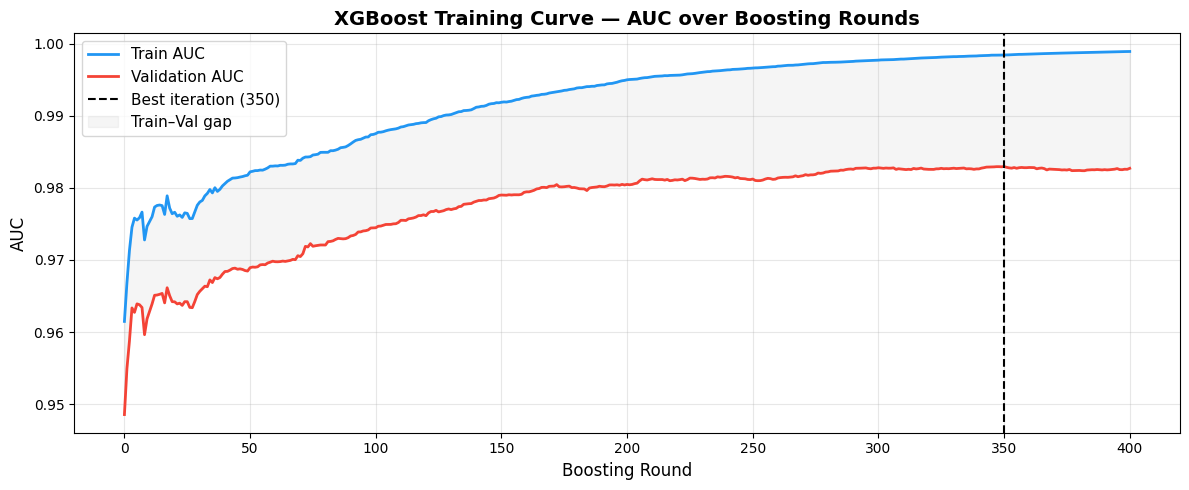

In [12]:
results = model.evals_result()
epochs  = len(results['validation_0']['auc'])
x_axis  = range(0, epochs)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(x_axis, results['validation_0']['auc'], color=REAL_COLOR, linewidth=2, label='Train AUC')
ax.plot(x_axis, results['validation_1']['auc'], color=FAKE_COLOR, linewidth=2, label='Validation AUC')
ax.axvline(model.best_iteration, color='black', linestyle='--', linewidth=1.5,
           label=f'Best iteration ({model.best_iteration})')
ax.fill_between(x_axis,
                results['validation_0']['auc'],
                results['validation_1']['auc'],
                alpha=0.08, color='gray', label='Train–Val gap')
ax.set_xlabel('Boosting Round', fontsize=12)
ax.set_ylabel('AUC', fontsize=12)
ax.set_title('XGBoost Training Curve — AUC over Boosting Rounds', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Step 8 — Evaluation
All metrics are computed on the **held-out test set** (never seen during training).  
Overfitting is flagged when train/test AUC gap exceeds 0.05.

In [13]:
y_pred      = model.predict(X_test)
y_pred_prob = model.predict_proba(X_test)[:, 1]

print("=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)
print(classification_report(y_test, y_pred, target_names=['Real', 'Fake']))

print(f"ROC-AUC : {roc_auc_score(y_test, y_pred_prob):.4f}")

cm = confusion_matrix(y_test, y_pred)
print(f"\nConfusion Matrix:")
print(f"  True  Real : {cm[0][0]}  |  False Fake: {cm[0][1]}")
print(f"  False Real : {cm[1][0]}  |  True  Fake: {cm[1][1]}")

sensitivity, specificity = specificity_sensitivity(y_test, y_pred)
print(f"Sensitivity (Recall Fake) : {sensitivity:.4f}")
print(f"Specificity (Recall Real) : {specificity:.4f}")

train_auc = roc_auc_score(y_train, model.predict_proba(X_train)[:, 1])
test_auc  = roc_auc_score(y_test,  y_pred_prob)
gap       = train_auc - test_auc

print(f"\nTrain AUC : {train_auc:.4f}")
print(f"Test  AUC : {test_auc:.4f}")
print(f"Gap       : {gap:.4f}  ", end="")
print("⚠️  Possible overfitting" if gap > 0.05 else "✅  No significant overfitting")

feat_imp = pd.Series(model.feature_importances_, index=X_train.columns)
print("\nTop 15 most important features:")
print(feat_imp.nlargest(15).to_string())
# ── Model Comparison Summary ──────────────────────────────────────────────

# XGBoost metrics (already computed above)
xgb_prec  = precision_score(y_test, y_pred,          pos_label=1)
xgb_rec   = recall_score(   y_test, y_pred,           pos_label=1)
xgb_f1    = f1_score(       y_test, y_pred,           pos_label=1)
xgb_auc   = roc_auc_score(  y_test, y_pred_prob)
xgb_ap    = average_precision_score(y_test, y_pred_prob)

# Naive Bayes metrics at tuned threshold
nb_prec   = precision_score(y_test, nb_preds_tuned,  pos_label=1)
nb_rec    = recall_score(   y_test, nb_preds_tuned,  pos_label=1)
nb_f1     = f1_score(       y_test, nb_preds_tuned,  pos_label=1)
nb_auc    = roc_auc_score(  y_test, nb_probs_test)
nb_ap     = average_precision_score(y_test, nb_probs_test)
xgb_sens, xgb_spec = specificity_sensitivity(y_test, y_pred)
nb_sens,  nb_spec  = specificity_sensitivity(y_test, nb_preds_tuned)

# Add RIPPER to variant_preds
variant_preds = {
    'XGBoost (0.5)':  y_pred,
    f'XGBoost ({best_t_f1:.2f})': (y_pred_prob >= best_t_f1).astype(int),
    'Naive Bayes':    nb_preds_tuned,
}
variant_preds['RIPPER (tuned)'] = ripper_preds_tuned

# Extended comparison table
rp_prec = precision_score(y_test, ripper_preds_tuned, pos_label=1)
rp_rec  = recall_score(   y_test, ripper_preds_tuned, pos_label=1)
rp_f1   = f1_score(       y_test, ripper_preds_tuned, pos_label=1)
rp_auc  = roc_auc_score(  y_test, ripper_probs_test)
rp_ap   = average_precision_score(y_test, ripper_probs_test)
rp_sens, rp_spec = specificity_sensitivity(y_test, ripper_preds_tuned)

xt_preds = (y_pred_prob >= best_t_f1).astype(int)
xt_prec  = precision_score(y_test, xt_preds, pos_label=1)
xt_rec   = recall_score(   y_test, xt_preds, pos_label=1)
xt_f1    = f1_score(       y_test, xt_preds, pos_label=1)
xt_sens, xt_spec = specificity_sensitivity(y_test, xt_preds)

comparison = pd.DataFrame({
    'Model':       ['Naive Bayes (tuned)', 'RIPPER (tuned)', 
                    'XGBoost (0.5)',        f'XGBoost ({best_t_f1:.2f})'],
    'Threshold':   [f'{best_thresh_nb:.2f}', f'{best_thresh_rp:.2f}', '0.50', f'{best_t_f1:.2f}'],
    'Precision':   [nb_prec,  rp_prec,  xgb_prec,  xt_prec],
    'Recall':      [nb_rec,   rp_rec,   xgb_rec,   xt_rec],
    'Sensitivity': [nb_sens,  rp_sens,  xgb_sens,  xt_sens],
    'Specificity': [nb_spec,  rp_spec,  xgb_spec,  xt_spec],
    'F1':          [nb_f1,    rp_f1,    xgb_f1,    xt_f1],
    'ROC-AUC':     [nb_auc,   rp_auc,   xgb_auc,   xgb_auc],
    'Avg Prec':    [nb_ap,    rp_ap,    xgb_ap,    xgb_ap],
}).set_index('Model').round(4)

print("\n" + "="*70)
print("MODEL COMPARISON — Held-out Test Set")
print("="*70)
print(comparison.to_string())

CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Real       1.00      0.96      0.98      3403
        Fake       0.58      0.94      0.71       173

    accuracy                           0.96      3576
   macro avg       0.79      0.95      0.85      3576
weighted avg       0.98      0.96      0.97      3576

ROC-AUC : 0.9899

Confusion Matrix:
  True  Real : 3283  |  False Fake: 120
  False Real : 10  |  True  Fake: 163
Sensitivity (Recall Fake) : 0.9422
Specificity (Recall Real) : 0.9647

Train AUC : 0.9961
Test  AUC : 0.9899
Gap       : 0.0062  ✅  No significant overfitting

Top 15 most important features:
hasCompanyProfile                               0.207391
previouslySeenAsFraudulent                      0.187142
hasCompanyLogo                                  0.101244
hasCompanyName                                  0.069429
required_education_Bachelor's Degree            0.030401
hasShortCompanyProfile                          0.026479
req

## Step 9 — Model Evaluation Visualisations
A comprehensive set of plots for the fraud detection model:
1. **Confusion matrix** (counts + normalised)
2. **ROC curve**
3. **Precision-Recall curve** (critical for imbalanced data)
4. **Predicted probability distribution**
5. **Top-20 feature importances**
6. **Threshold sensitivity** (precision, recall, F1 vs. threshold)

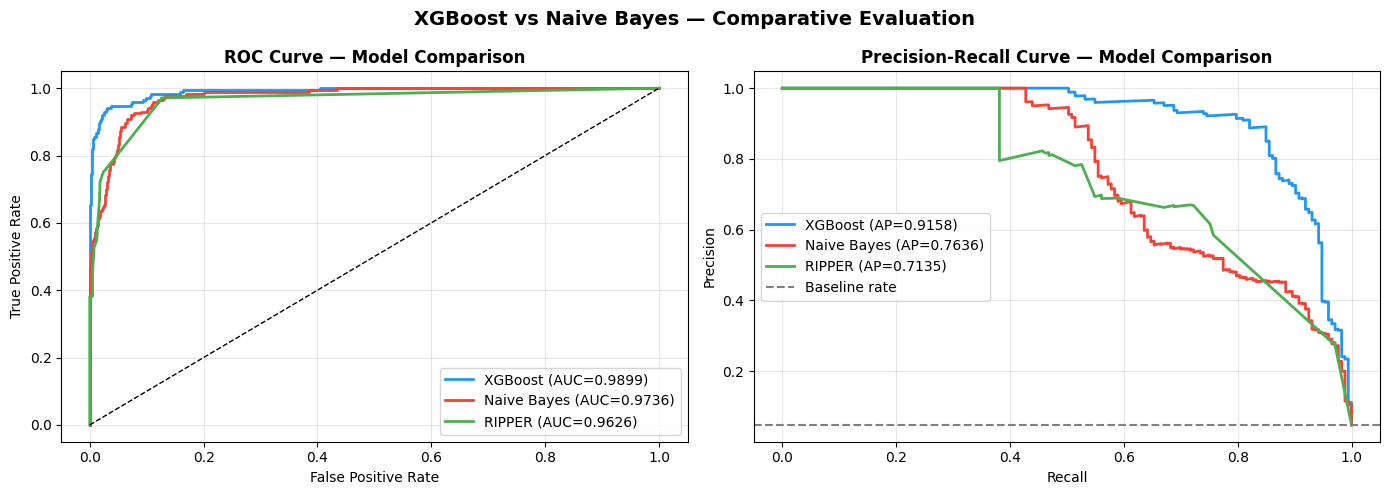

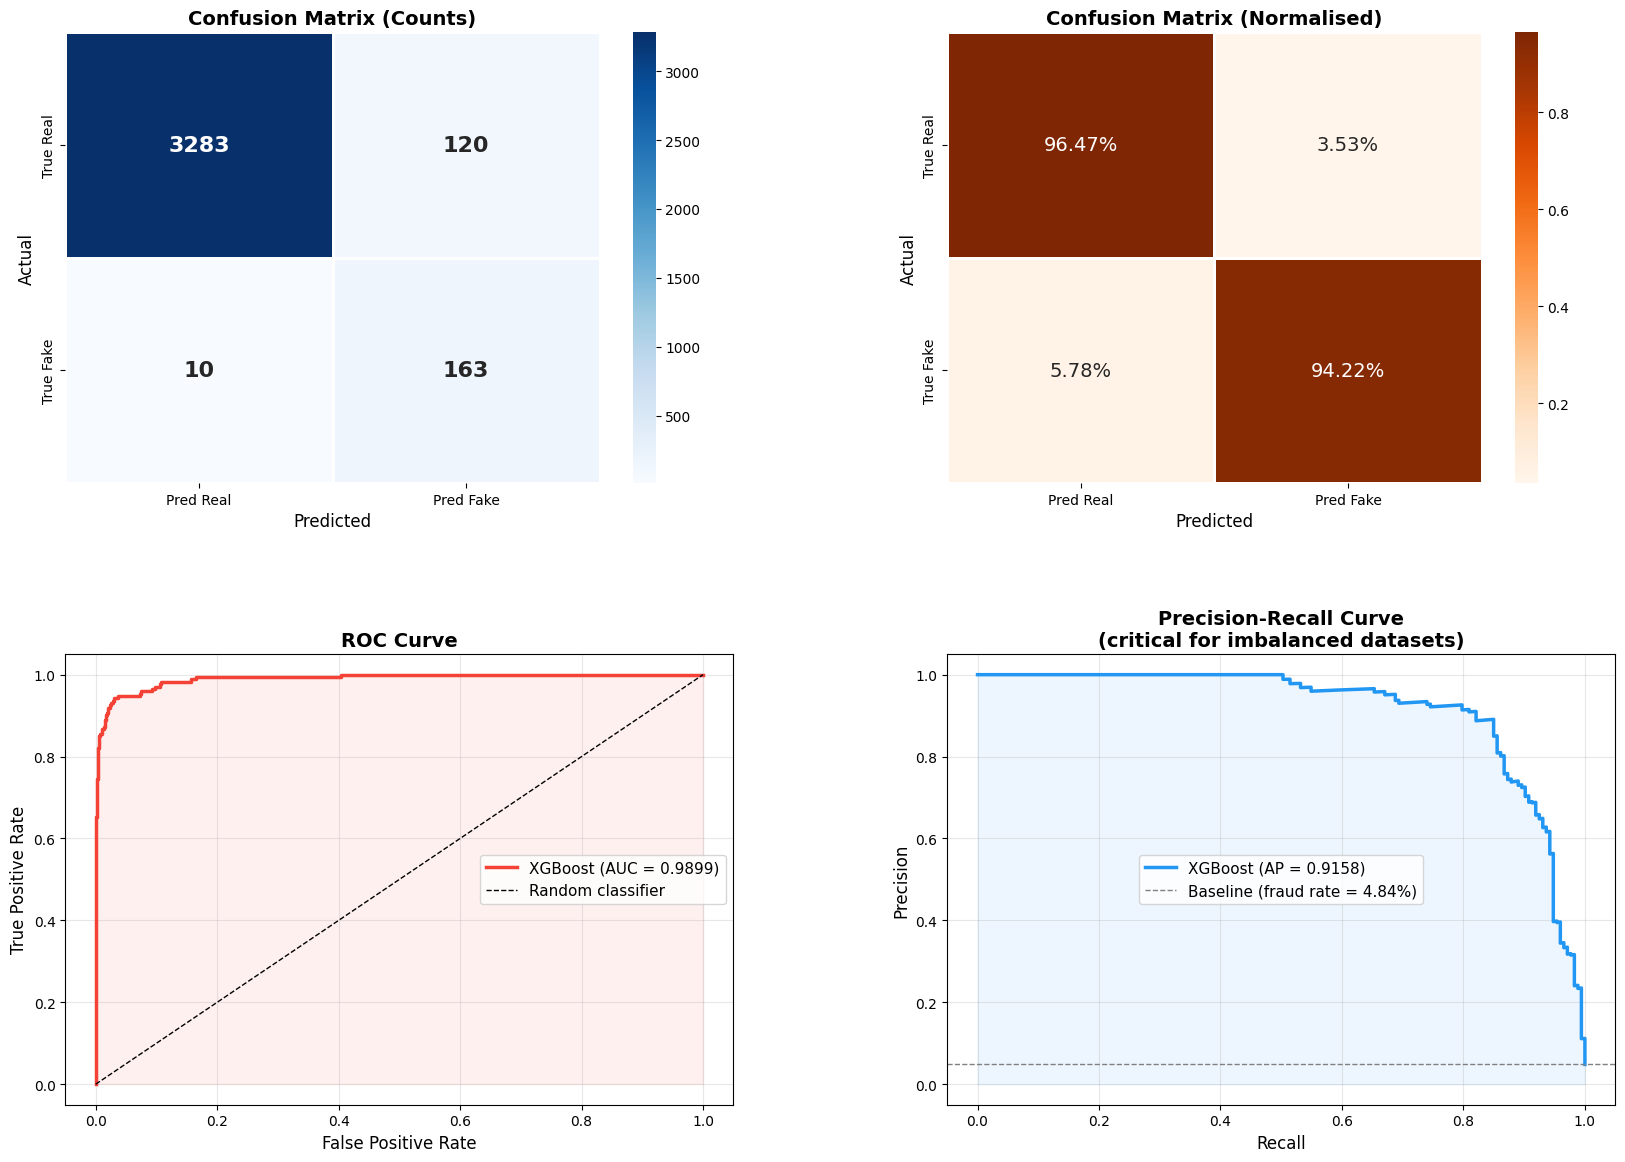

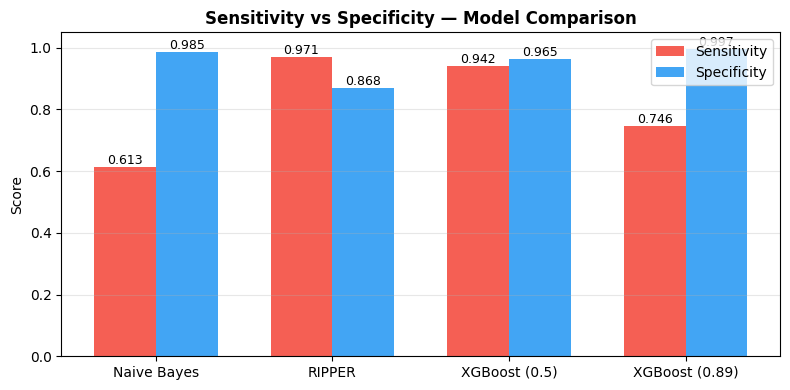

<Figure size 640x480 with 0 Axes>

Saved: /kaggle/working/evaluation_dashboard.png


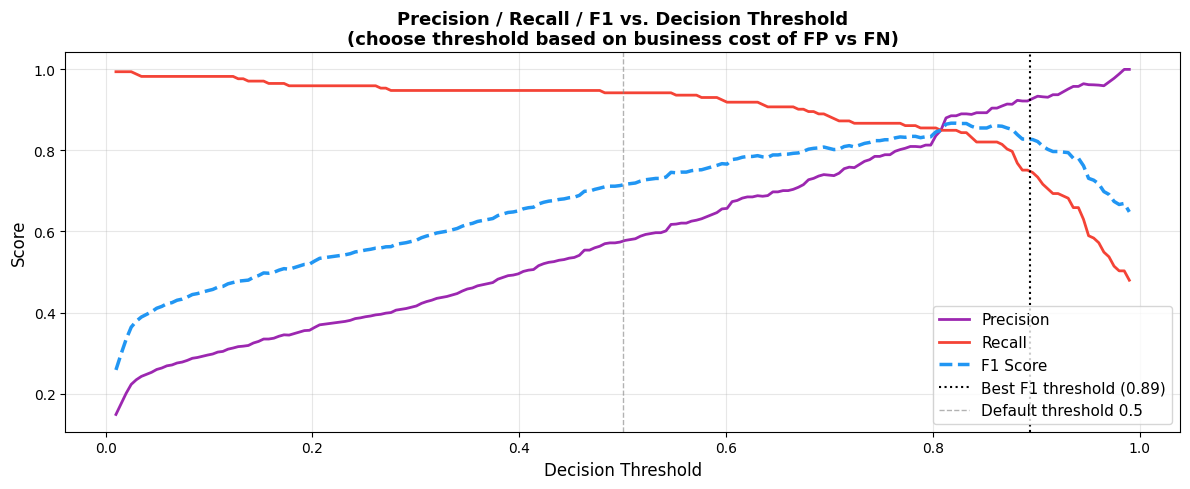

Validation-selected F1 threshold: 0.894  |  test F1 at that threshold: 0.8269


In [14]:
# ── Comparative ROC and PR curves: XGBoost vs Naive Bayes ───────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC curves
for probs, label, color in [
    (y_pred_prob,    'XGBoost (AUC={:.4f})'.format(xgb_auc),  '#2196F3'),
    (nb_probs_test,  'Naive Bayes (AUC={:.4f})'.format(nb_auc), '#F44336'),
    (ripper_probs_test,  f'RIPPER (AUC={rp_auc:.4f})',      '#4CAF50'),
]:
    fpr, tpr, _ = roc_curve(y_test, probs)
    axes[0].plot(fpr, tpr, label=label, linewidth=2, color=color)
axes[0].plot([0,1],[0,1], 'k--', linewidth=1)
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve — Model Comparison', fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Precision-Recall curves
for probs, label, color in [
    (y_pred_prob,    'XGBoost (AP={:.4f})'.format(xgb_ap),    '#2196F3'),
    (nb_probs_test,  'Naive Bayes (AP={:.4f})'.format(nb_ap),  '#F44336'),
    (ripper_probs_test,  f'RIPPER (AP={rp_ap:.4f})',      '#4CAF50'),
]:
    prec, rec, _ = precision_recall_curve(y_test, probs)
    axes[1].plot(rec, prec, label=label, linewidth=2, color=color)
axes[1].axhline(y_test.mean(), color='gray', linestyle='--', label='Baseline rate')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curve — Model Comparison', fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle('XGBoost vs Naive Bayes — Comparative Evaluation', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

fig = plt.figure(figsize=(20, 22))
gs  = gridspec.GridSpec(3, 2, figure=fig, hspace=0.38, wspace=0.32)

# ─────────────────────────────────────────────────────────────────────────────
# 1a. Confusion Matrix — raw counts
# ─────────────────────────────────────────────────────────────────────────────
ax1 = fig.add_subplot(gs[0, 0])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred Real', 'Pred Fake'],
            yticklabels=['True Real', 'True Fake'],
            linewidths=2, linecolor='white', ax=ax1,
            annot_kws={'size': 16, 'weight': 'bold'})
ax1.set_title('Confusion Matrix (Counts)', fontsize=14, fontweight='bold')
ax1.set_xlabel('Predicted', fontsize=12)
ax1.set_ylabel('Actual', fontsize=12)

# ─────────────────────────────────────────────────────────────────────────────
# 1b. Confusion Matrix — normalised (rates)
# ─────────────────────────────────────────────────────────────────────────────
ax2 = fig.add_subplot(gs[0, 1])
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Oranges',
            xticklabels=['Pred Real', 'Pred Fake'],
            yticklabels=['True Real', 'True Fake'],
            linewidths=2, linecolor='white', ax=ax2,
            annot_kws={'size': 14})
ax2.set_title('Confusion Matrix (Normalised)', fontsize=14, fontweight='bold')
ax2.set_xlabel('Predicted', fontsize=12)
ax2.set_ylabel('Actual', fontsize=12)

# ─────────────────────────────────────────────────────────────────────────────
# 2. ROC Curve
# ─────────────────────────────────────────────────────────────────────────────
ax3 = fig.add_subplot(gs[1, 0])
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
auc_score   = roc_auc_score(y_test, y_pred_prob)
ax3.plot(fpr, tpr, color=FAKE_COLOR, linewidth=2.5, label=f'XGBoost (AUC = {auc_score:.4f})')
ax3.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random classifier')
ax3.fill_between(fpr, tpr, alpha=0.08, color=FAKE_COLOR)
ax3.set_xlabel('False Positive Rate', fontsize=12)
ax3.set_ylabel('True Positive Rate', fontsize=12)
ax3.set_title('ROC Curve', fontsize=14, fontweight='bold')
ax3.legend(fontsize=11)
ax3.grid(True, alpha=0.3)

# ─────────────────────────────────────────────────────────────────────────────
# 3. Precision-Recall Curve
# ─────────────────────────────────────────────────────────────────────────────
ax4 = fig.add_subplot(gs[1, 1])
precision, recall, _ = precision_recall_curve(y_test, y_pred_prob)
ap = average_precision_score(y_test, y_pred_prob)
ax4.plot(recall, precision, color=REAL_COLOR, linewidth=2.5, label=f'XGBoost (AP = {ap:.4f})')
baseline = y_test.mean()
ax4.axhline(baseline, color='gray', linestyle='--', linewidth=1,
            label=f'Baseline (fraud rate = {baseline:.2%})')
ax4.fill_between(recall, precision, alpha=0.08, color=REAL_COLOR)
ax4.set_xlabel('Recall', fontsize=12)
ax4.set_ylabel('Precision', fontsize=12)
ax4.set_title('Precision-Recall Curve\n(critical for imbalanced datasets)', fontsize=14, fontweight='bold')
ax4.legend(fontsize=11)
ax4.grid(True, alpha=0.3)
# ─────────────────────────────────────────────────────────────────────────────
# 4. Sensitivity / Specificity bar chart ──────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 4))

xgb_sens_tuned, xgb_spec_tuned = specificity_sensitivity(
    y_test, (y_pred_prob >= best_t_f1).astype(int)
)

models    = ['Naive Bayes', 'RIPPER', 'XGBoost (0.5)', f'XGBoost ({best_t_f1:.2f})']
sens_vals = [nb_sens,  rp_sens,  xgb_sens,  xgb_sens_tuned]
spec_vals = [nb_spec,  rp_spec,  xgb_spec,  xgb_spec_tuned]

x = np.arange(len(models))
w = 0.35
ax.bar(x - w/2, sens_vals, w, label='Sensitivity', color='#F44336', alpha=0.85)
ax.bar(x + w/2, spec_vals, w, label='Specificity', color='#2196F3', alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(0, 1.05)
ax.set_ylabel('Score')
ax.set_title('Sensitivity vs Specificity — Model Comparison', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

for i, (s, sp) in enumerate(zip(sens_vals, spec_vals)):
    ax.text(i - w/2, s + 0.01, f'{s:.3f}', ha='center', fontsize=9)
    ax.text(i + w/2, sp + 0.01, f'{sp:.3f}', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

# ─────────────────────────────────────────────────────────────────────────────
# 5. Predicted Probability Distribution
# ─────────────────────────────────────────────────────────────────────────────
ax5 = fig.add_subplot(gs[2, 0])
for label, color, name in [(0, REAL_COLOR, 'Real'), (1, FAKE_COLOR, 'Fake')]:
    probs = y_pred_prob[y_test == label]
    ax5.hist(probs, bins=50, alpha=0.6, color=color, label=f'{name} (n={len(probs):,})', density=True)
ax5.axvline(0.5, color='black', linestyle='--', linewidth=1.5, label='Default threshold 0.5')
ax5.set_xlabel('Predicted Probability of Fraud', fontsize=12)
ax5.set_ylabel('Density', fontsize=12)
ax5.set_title('Predicted Probability Distribution by True Class', fontsize=14, fontweight='bold')
ax5.legend(fontsize=11)
ax5.grid(True, alpha=0.3)

# ─────────────────────────────────────────────────────────────────────────────
# 6. Top-20 Feature Importances
# ─────────────────────────────────────────────────────────────────────────────
ax6 = fig.add_subplot(gs[2, 1])
top20 = feat_imp.nlargest(20).sort_values()
colors_fi = [FAKE_COLOR if i >= 15 else ('#FF9800' if i >= 10 else REAL_COLOR)
             for i in range(len(top20))]
ax6.barh(top20.index, top20.values, color=colors_fi, edgecolor='none', alpha=0.85)
ax6.set_xlabel('Feature Importance Score', fontsize=12)
ax6.set_title('Top 20 Feature Importances (XGBoost)', fontsize=14, fontweight='bold')
ax6.grid(True, axis='x', alpha=0.3)

plt.suptitle('XGBoost Fraud Detector — Full Evaluation Dashboard', fontsize=17,
             fontweight='bold', y=1.01)
plt.savefig('/kaggle/working/evaluation_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: /kaggle/working/evaluation_dashboard.png")

# ─────────────────────────────────────────────────────────────────────────────
# 7. Threshold Sensitivity (standalone plot)
# ─────────────────────────────────────────────────────────────────────────────
from sklearn.metrics import f1_score

thresholds = np.linspace(0.01, 0.99, 200)
precisions, recalls, f1s = [], [], []
for t in thresholds:
    preds = (y_pred_prob >= t).astype(int)
    precisions.append(precision_score(y_test, preds, zero_division=0) if preds.sum() > 0 else 0)
    recalls.append(recall_score(y_test, preds, zero_division=0))
    f1s.append(f1_score(y_test, preds, zero_division=0))


fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(thresholds, precisions, color='#9C27B0', linewidth=2, label='Precision')
ax.plot(thresholds, recalls,    color=FAKE_COLOR,  linewidth=2, label='Recall')
ax.plot(thresholds, f1s,        color=REAL_COLOR,  linewidth=2.5, label='F1 Score', linestyle='--')
best_t = best_t_f1
ax.axvline(best_t, color='black', linestyle=':', linewidth=1.5,
           label=f'Best F1 threshold ({best_t:.2f})')
ax.axvline(0.5, color='gray', linestyle='--', linewidth=1, alpha=0.6, label='Default threshold 0.5')
ax.set_xlabel('Decision Threshold', fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Precision / Recall / F1 vs. Decision Threshold\n(choose threshold based on business cost of FP vs FN)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('/kaggle/working/threshold_sensitivity.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Validation-selected F1 threshold: {best_t:.3f}  |  test F1 at that threshold: {f1_score(y_test, (y_pred_prob >= best_t).astype(int)):.4f}")

## Step 10 — Fine-Tuning for Precision & Recall on Fake Class

Current baseline (threshold 0.5): **Precision 0.58 / Recall 0.94** on Fake.
We attack this from four angles simultaneously:

| Lever | What it does |
|---|---|
| **Optimal threshold** | Shift the decision boundary away from 0.5 using F1/F2 optimisation |
| **SMOTE oversampling** | Synthesise minority-class examples so the model sees more fraud signal |
| **Bayesian hyperparameter search** | Find better `max_depth`, `learning_rate`, `gamma`, etc. via `optuna` |
| **Calibrated probabilities** | Isotonic regression to make predicted probabilities better-ranked |

All tuning uses cross-validation on **train only** — test set stays untouched.

In [15]:

import subprocess, sys
for pkg in ['optuna', 'imbalanced-learn']:
    subprocess.run([sys.executable, '-m', 'pip', 'install', pkg, '-q'], check=False)

import warnings
warnings.filterwarnings('ignore')

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

REAL_COLOR = '#2196F3'
FAKE_COLOR = '#F44336'
RANDOM_STATE = 42
CV_FOLDS = 5

print("Libraries ready.")

Libraries ready.


### A — Optimal Decision Threshold (fastest win)
Before retraining anything, find the threshold that maximises **F2-score** on the validation set.  
F2 weights recall twice as much as precision — appropriate when missing a fake job is worse than a false alarm.


── Sensitivity / Specificity per Variant ──
XGBoost (0.5)                   Sensitivity: 0.9422  Specificity: 0.9647
XGBoost (0.89)                  Sensitivity: 0.7457  Specificity: 0.9971
Naive Bayes                     Sensitivity: 0.6127  Specificity: 0.9847
RIPPER (tuned)                  Sensitivity: 0.9711  Specificity: 0.8684
Best F1 threshold : 0.894  →  val F1=0.7956
Best F2 threshold : 0.650  →  val F2=0.8047

  [Default (0.50)]  Precision=0.576  Recall=0.942  F1=0.715
  [Best F1 (0.89)]  Precision=0.928  Recall=0.746  F1=0.827
  [Best F2 (0.65)]  Precision=0.698  Recall=0.908  F1=0.789


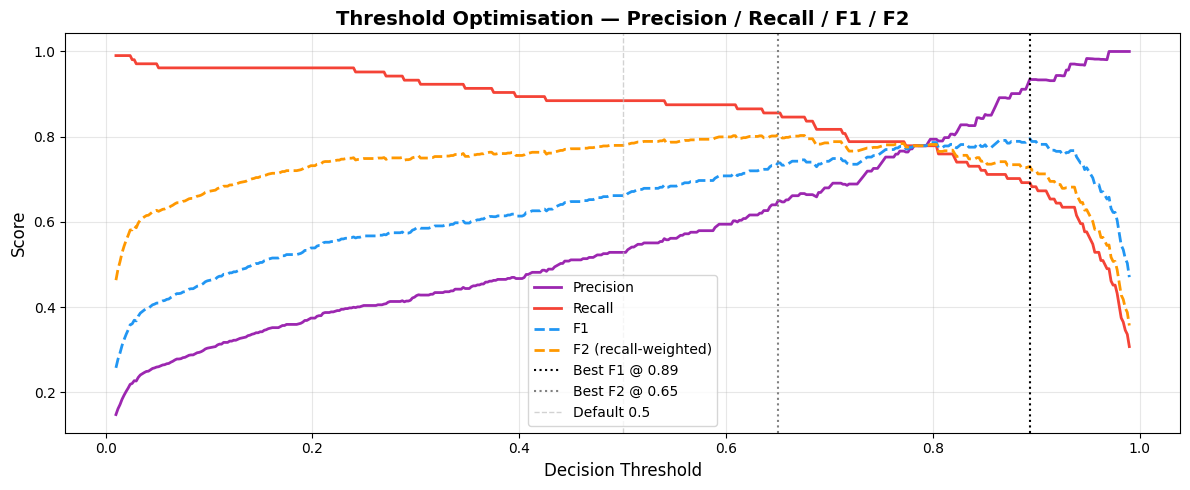

In [16]:
# Use the already-trained model's probabilities
thresholds = np.linspace(0.01, 0.99, 500)

print("\n── Sensitivity / Specificity per Variant ──")
for name, preds in variant_preds.items():
    sens, spec = specificity_sensitivity(y_test, preds)
    print(f"{name:30s}  Sensitivity: {sens:.4f}  Specificity: {spec:.4f}")


best_f1, best_f2, best_t_f1, best_t_f2 = 0, 0, 0.5, 0.5
rows = []
for t in thresholds:
    preds = (val_prob >= t).astype(int)                       # validation probabilities
    p  = precision_score(y_val, preds, zero_division=0)
    r  = recall_score(y_val, preds, zero_division=0)
    f1 = f1_score(y_val, preds, zero_division=0)
    f2 = (1 + 4) * p * r / (4 * p + r + 1e-9)
    rows.append({'threshold': t, 'precision': p, 'recall': r, 'f1': f1, 'f2': f2})
    if f1 > best_f1: best_f1, best_t_f1 = f1, t
    if f2 > best_f2: best_f2, best_t_f2 = f2, t
    

df_thresh = pd.DataFrame(rows)

print(f"Best F1 threshold : {best_t_f1:.3f}  →  val F1={best_f1:.4f}")
print(f"Best F2 threshold : {best_t_f2:.3f}  →  val F2={best_f2:.4f}")
print()

for label, t in [('Default (0.50)', 0.50), (f'Best F1 ({best_t_f1:.2f})', best_t_f1), (f'Best F2 ({best_t_f2:.2f})', best_t_f2)]:
    preds = (y_pred_prob >= t).astype(int)
    print(f"  [{label}]  Precision={precision_score(y_test,preds,zero_division=0):.3f}  "
          f"Recall={recall_score(y_test,preds,zero_division=0):.3f}  "
          f"F1={f1_score(y_test,preds,zero_division=0):.3f}")

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df_thresh['threshold'], df_thresh['precision'], color='#9C27B0', lw=2, label='Precision')
ax.plot(df_thresh['threshold'], df_thresh['recall'],    color=FAKE_COLOR,  lw=2, label='Recall')
ax.plot(df_thresh['threshold'], df_thresh['f1'],        color=REAL_COLOR,  lw=2, ls='--', label='F1')
ax.plot(df_thresh['threshold'], df_thresh['f2'],        color='#FF9800',   lw=2, ls='--', label='F2 (recall-weighted)')
ax.axvline(best_t_f1, color='black',  ls=':', lw=1.5, label=f'Best F1 @ {best_t_f1:.2f}')
ax.axvline(best_t_f2, color='gray',   ls=':', lw=1.5, label=f'Best F2 @ {best_t_f2:.2f}')
ax.axvline(0.5,       color='silver', ls='--', lw=1,  label='Default 0.5', alpha=0.7)
ax.set_xlabel('Decision Threshold', fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Threshold Optimisation — Precision / Recall / F1 / F2', fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### B — SMOTE Oversampling + Retrain
Synthesise new minority-class examples in feature space so XGBoost trains on a more balanced dataset.  
We combine SMOTE with the tuned threshold from Step A.

In [17]:
smote = SMOTE(sampling_strategy=0.3, random_state=RANDOM_STATE, k_neighbors=5)
X_tr_sm, y_tr_sm = smote.fit_resample(X_tr, y_tr)

print(f"Before SMOTE — Real: {(y_tr==0).sum():,}  Fake: {(y_tr==1).sum():,}")
print(f"After  SMOTE — Real: {(y_tr_sm==0).sum():,}  Fake: {(y_tr_sm==1).sum():,}")

# Recompute scale_pos_weight on the resampled set
spw_sm = (y_tr_sm == 0).sum() / (y_tr_sm == 1).sum()

model_smote = xgb.XGBClassifier(
    n_estimators          = 1000,
    learning_rate         = 0.05,
    max_depth             = 4,
    min_child_weight      = 5,
    subsample             = 0.8,
    colsample_bytree      = 0.8,
    reg_alpha             = 0.1,
    reg_lambda            = 1.0,
    gamma                 = 0.1,
    scale_pos_weight      = spw_sm,
    early_stopping_rounds = 50,
    objective             = 'binary:logistic',
    eval_metric           = 'auc',
    random_state          = RANDOM_STATE,
    n_jobs                = -1,
)
model_smote.fit(X_tr_sm, y_tr_sm,
                eval_set=[(X_val, y_val)],
                verbose=False)

prob_smote = model_smote.predict_proba(X_test)[:, 1]

# Apply best F1 threshold from Step A
preds_smote = (prob_smote >= best_t_f1).astype(int)
print(f"\nSMOTE model @ threshold {best_t_f1:.2f}:")
print(f"  Precision : {precision_score(y_test, preds_smote, zero_division=0):.4f}")
print(f"  Recall    : {recall_score(y_test, preds_smote, zero_division=0):.4f}")
print(f"  F1        : {f1_score(y_test, preds_smote, zero_division=0):.4f}")
print(f"  ROC-AUC   : {roc_auc_score(y_test, prob_smote):.4f}")

Before SMOTE — Real: 11,569  Fake: 589
After  SMOTE — Real: 11,569  Fake: 3,470

SMOTE model @ threshold 0.89:
  Precision : 0.9431
  Recall    : 0.6705
  F1        : 0.7838
  ROC-AUC   : 0.9884


### C — Bayesian Hyperparameter Search (Optuna)
Search over the most impactful XGBoost hyperparameters using cross-validated PR-AUC, with SMOTE applied inside each.  
30 trials typically converges well; increase for a more thorough search.

In [18]:
from imblearn.pipeline import Pipeline as ImbPipeline

def objective(trial):
    params = dict(
        n_estimators      = trial.suggest_int('n_estimators', 200, 1200),
        learning_rate     = trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        max_depth         = trial.suggest_int('max_depth', 3, 7),
        min_child_weight  = trial.suggest_int('min_child_weight', 1, 10),
        subsample         = trial.suggest_float('subsample', 0.6, 1.0),
        colsample_bytree  = trial.suggest_float('colsample_bytree', 0.5, 1.0),
        reg_alpha         = trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        reg_lambda        = trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
        gamma             = trial.suggest_float('gamma', 0.0, 1.0),
        scale_pos_weight  = spw_sm,
        objective='binary:logistic', eval_metric='auc',
        random_state=RANDOM_STATE, n_jobs=-1, verbosity=0,
    )
    pipe = ImbPipeline([
        ('smote', SMOTE(sampling_strategy=0.3, random_state=RANDOM_STATE, k_neighbors=5)),
        ('clf',   xgb.XGBClassifier(**params)),
    ])
    cv  = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
    oof = cross_val_predict(pipe, X_tr, y_tr, cv=cv, method='predict_proba')[:, 1]  # original X_tr, y_tr
    return average_precision_score(y_tr, oof)

study = optuna.create_study(direction='maximize',
                            sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=30, show_progress_bar=True)

print(f"\nBest CV PR-AUC  : {study.best_value:.4f}")
print(f"Best params : {study.best_params}")

  0%|          | 0/30 [00:00<?, ?it/s]


Best CV PR-AUC  : 0.8850
Best params : {'n_estimators': 1093, 'learning_rate': 0.04837962254435269, 'max_depth': 7, 'min_child_weight': 1, 'subsample': 0.8406210499670551, 'colsample_bytree': 0.7995841296400897, 'reg_alpha': 0.07272738925806131, 'reg_lambda': 0.04680143548789867, 'gamma': 0.13216827715702534}


### D — Retrain with Optimal Hyperparameters + Calibration
Train the final model on SMOTE data with Optuna's best params, then apply isotonic calibration to sharpen the probability estimates.

In [19]:
best_params = study.best_params.copy()
best_params.update({
    'scale_pos_weight' : spw_sm,
    'objective'        : 'binary:logistic',
    'eval_metric'      : 'auc',
    'random_state'     : RANDOM_STATE,
    'n_jobs'           : -1,
    'verbosity'        : 0,
    'early_stopping_rounds': 50,
})

model_tuned = xgb.XGBClassifier(**best_params)
model_tuned.fit(X_tr_sm, y_tr_sm,
                eval_set=[(X_val, y_val)],
                verbose=False)

# Isotonic calibration — wraps the tuned model
# cv='prefit' means: model already trained, just fit the calibrator
calibrated = CalibratedClassifierCV(model_tuned, cv='prefit', method='isotonic')
calibrated.fit(X_val, y_val)

prob_tuned = calibrated.predict_proba(X_test)[:, 1]
preds_tuned = (prob_tuned >= best_t_f1).astype(int)

print("Tuned + Calibrated model results:")
print(f"  Precision : {precision_score(y_test, preds_tuned, zero_division=0):.4f}")
print(f"  Recall    : {recall_score(y_test, preds_tuned, zero_division=0):.4f}")
print(f"  F1        : {f1_score(y_test, preds_tuned, zero_division=0):.4f}")
print(f"  ROC-AUC   : {roc_auc_score(y_test, prob_tuned):.4f}")

Tuned + Calibrated model results:
  Precision : 0.9818
  Recall    : 0.6243
  F1        : 0.7633
  ROC-AUC   : 0.9875


### E — Comparison Dashboard
Side-by-side comparison of all model variants across every key metric.

                           Precision  Recall      F1     AUC
Baseline\n(threshold 0.5)     0.5760  0.9422  0.7149  0.9899
Threshold only\n(0.89)        0.9281  0.7457  0.8269  0.9899
SMOTE\n(0.89)                 0.9431  0.6705  0.7838  0.9884
Tuned+Calib\n(0.89)           0.9818  0.6243  0.7633  0.9875


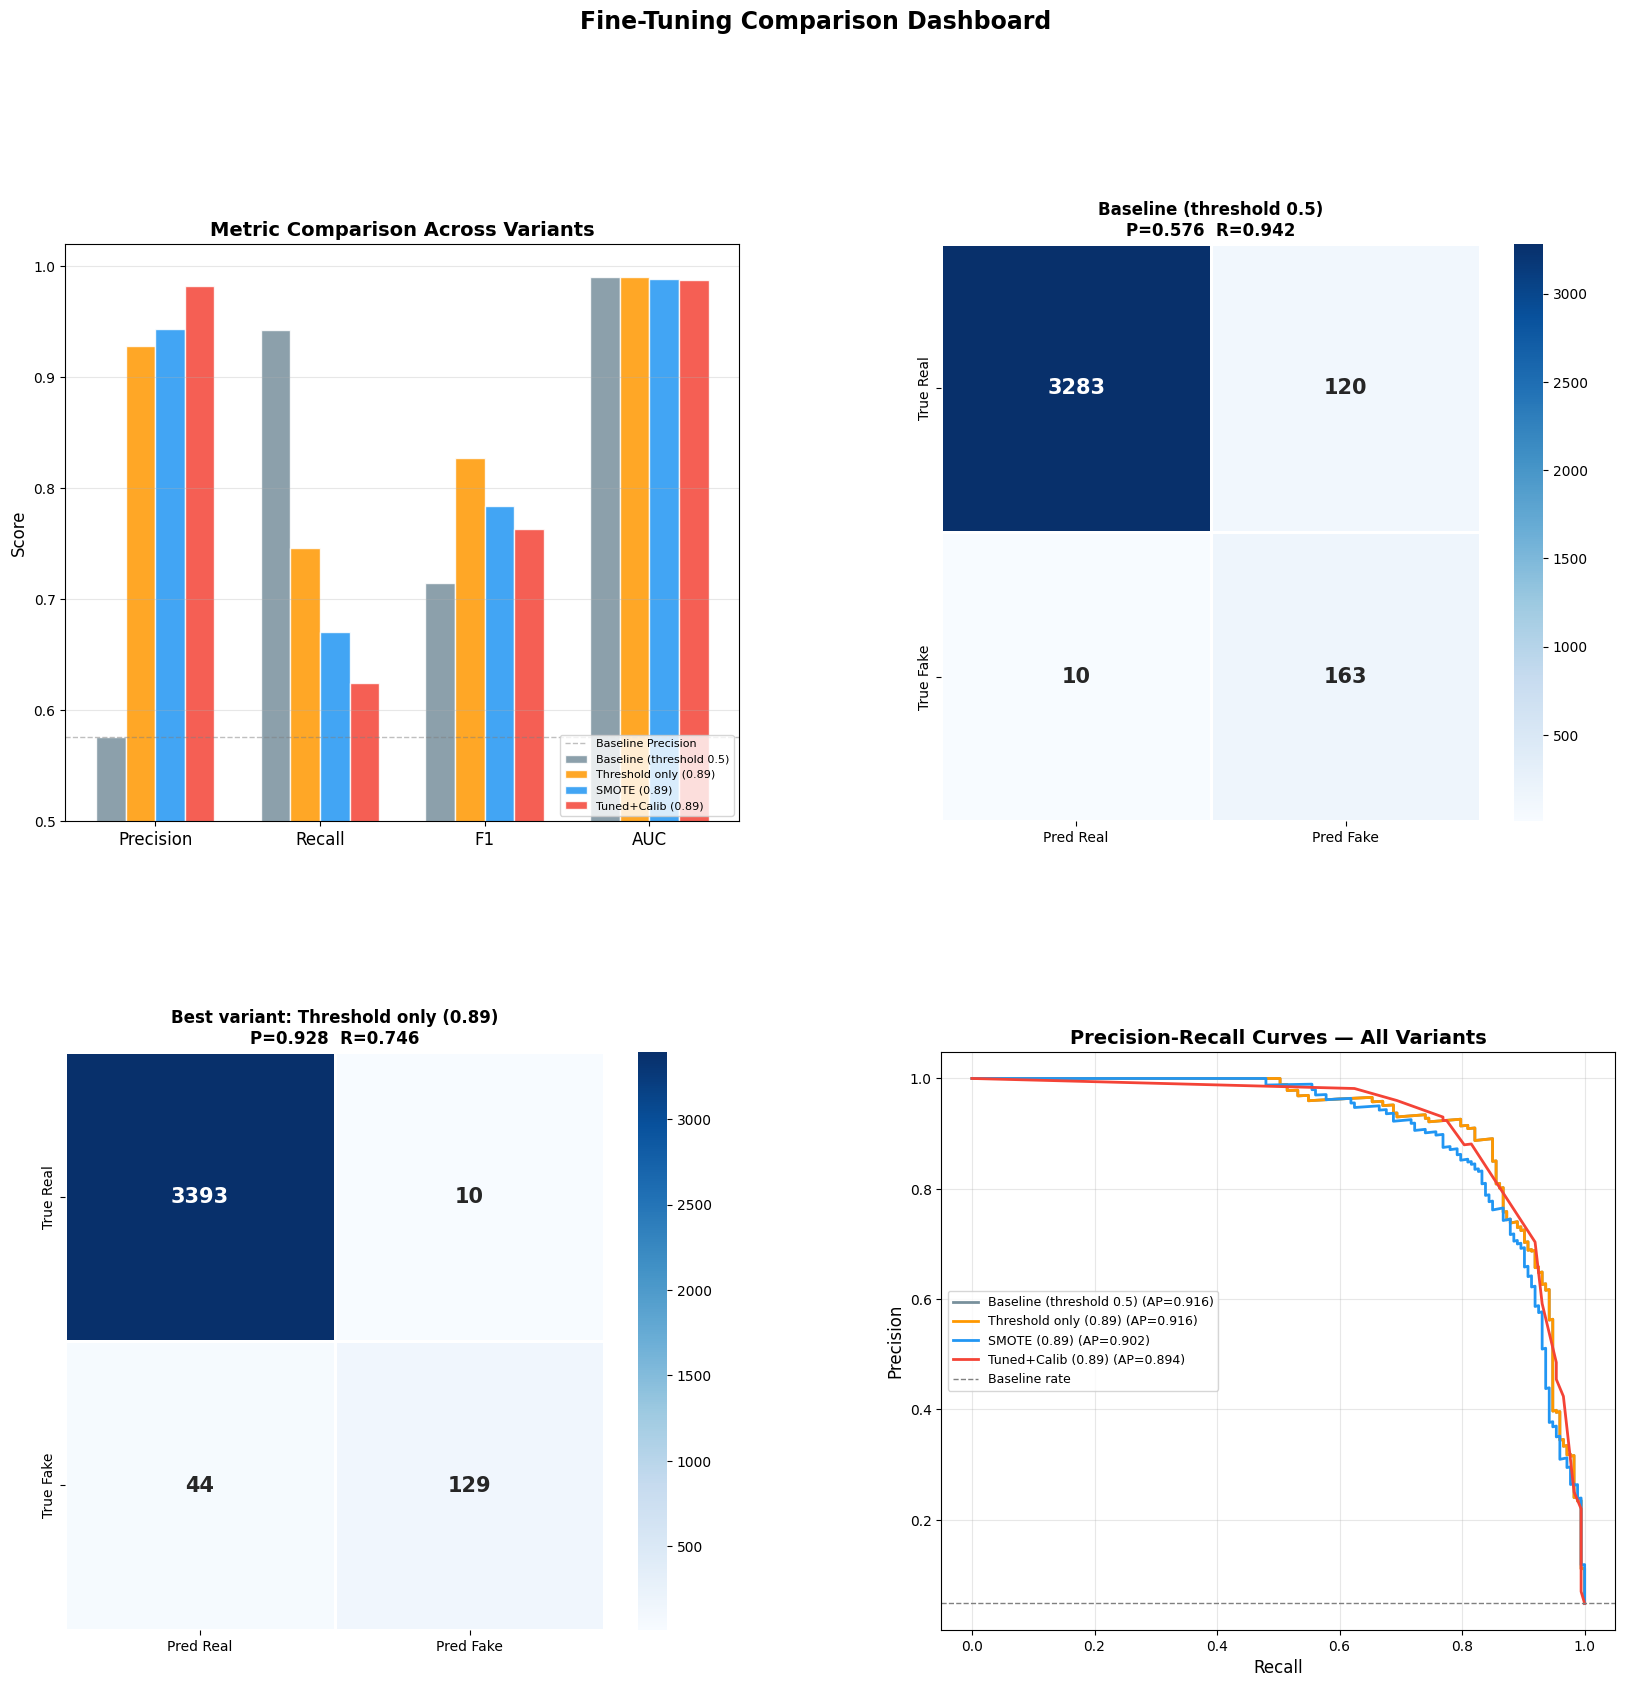

Saved: /kaggle/working/finetuning_dashboard.png


In [20]:
# ── Collect all variants ────────────────────────────────────────────────────
variants = {
    'Baseline\n(threshold 0.5)':        (y_pred_prob,  0.50),
    f'Threshold only\n({best_t_f1:.2f})': (y_pred_prob,  best_t_f1),
    f'SMOTE\n({best_t_f1:.2f})':          (prob_smote,   best_t_f1),
    f'Tuned+Calib\n({best_t_f1:.2f})':    (prob_tuned,   best_t_f1),
}

results = {}
for name, (probs, t) in variants.items():
    preds = (probs >= t).astype(int)
    results[name] = {
        'Precision': precision_score(y_test, preds, zero_division=0),
        'Recall':    recall_score(y_test, preds, zero_division=0),
        'F1':        f1_score(y_test, preds, zero_division=0),
        'AUC':       roc_auc_score(y_test, probs),
    }

df_results = pd.DataFrame(results).T
print(df_results.round(4).to_string())

# ── Dashboard ────────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(20, 18))
gs  = gridspec.GridSpec(2, 2, figure=fig, hspace=0.4, wspace=0.3)

names  = list(results.keys())
colors = ['#78909C', '#FF9800', REAL_COLOR, FAKE_COLOR]

# 1. Metric comparison bar chart
ax1 = fig.add_subplot(gs[0, 0])
metrics = ['Precision', 'Recall', 'F1', 'AUC']
x = np.arange(len(metrics))
w = 0.18
for i, (name, color) in enumerate(zip(names, colors)):
    vals = [results[name][m] for m in metrics]
    bars = ax1.bar(x + i*w, vals, w, label=name.replace('\n', ' '), color=color, alpha=0.85, edgecolor='white')
ax1.axhline(results[names[0]]['Precision'], color='gray', ls='--', lw=1, alpha=0.5, label='Baseline Precision')
ax1.set_xticks(x + w*1.5)
ax1.set_xticklabels(metrics, fontsize=12)
ax1.set_ylim(0.5, 1.02)
ax1.set_ylabel('Score', fontsize=12)
ax1.set_title('Metric Comparison Across Variants', fontsize=14, fontweight='bold')
ax1.legend(fontsize=8, loc='lower right')
ax1.grid(True, axis='y', alpha=0.3)

# 2. Confusion matrices — baseline vs best
best_name = max(results, key=lambda n: results[n]['F1'])
best_probs, best_t = variants[best_name]
best_preds = (best_probs >= best_t).astype(int)

for ax, preds, title in [
    (fig.add_subplot(gs[0, 1]), y_pred,     'Baseline (threshold 0.5)'),
    (fig.add_subplot(gs[1, 0]), best_preds, f'Best variant: {best_name.replace(chr(10)," ")}'),
]:
    cm_v = confusion_matrix(y_test, preds)
    sns.heatmap(cm_v, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Pred Real','Pred Fake'],
                yticklabels=['True Real','True Fake'],
                linewidths=2, linecolor='white', ax=ax,
                annot_kws={'size': 15, 'weight': 'bold'})
    p = precision_score(y_test, preds, zero_division=0)
    r = recall_score(y_test, preds, zero_division=0)
    ax.set_title(f'{title}\nP={p:.3f}  R={r:.3f}', fontsize=12, fontweight='bold')

# 3. PR curves for all variants
ax4 = fig.add_subplot(gs[1, 1])
for (name, (probs, _)), color in zip(variants.items(), colors):
    prec, rec, _ = precision_recall_curve(y_test, probs)
    ap = average_precision_score(y_test, probs)
    ax4.plot(rec, prec, color=color, lw=2, label=f'{name.replace(chr(10)," ")} (AP={ap:.3f})')
ax4.axhline(y_test.mean(), color='gray', ls='--', lw=1, label='Baseline rate')
ax4.set_xlabel('Recall', fontsize=12)
ax4.set_ylabel('Precision', fontsize=12)
ax4.set_title('Precision-Recall Curves — All Variants', fontsize=14, fontweight='bold')
ax4.legend(fontsize=9)
ax4.grid(True, alpha=0.3)

plt.suptitle('Fine-Tuning Comparison Dashboard', fontsize=17, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('/kaggle/working/finetuning_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: /kaggle/working/finetuning_dashboard.png")